# Exploratory Data Analysis (EDA)

### Импорт библиотек

In [ ]:
import pandas as pd
import numpy as np
import os
from ydata_profiling import ProfileReport
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

### Загрузка данных

In [ ]:
#!kaggle competitions download -c home-credit-default-risk -p ../data/ && unzip ../data/*.zip -d ../data/raw/

### Чтение данных таблиц train и test

In [ ]:
df_train = pd.read_csv('../data/raw/application_train.csv')
print('Training data shape: ', df_train.shape)
df_train.head()

In [ ]:
df_test = pd.read_csv('../data/raw/application_test.csv')
print('Testing data shape: ', df_test.shape)
df_test.head()

---

# Описание датасета

---

Данные предоставлены компанией [Home Credit](http://www.homecredit.net/about-us.aspx), которая занимается предоставлением кредитов населению, не имеющему банковских счетов. Прогнозирование того, погасит ли клиент кредит или у него возникнут трудности с погашением.

Имеется 7 различных источников данных. Ниже представлена схема связей между ними.

<div style="max-width: 600px;">

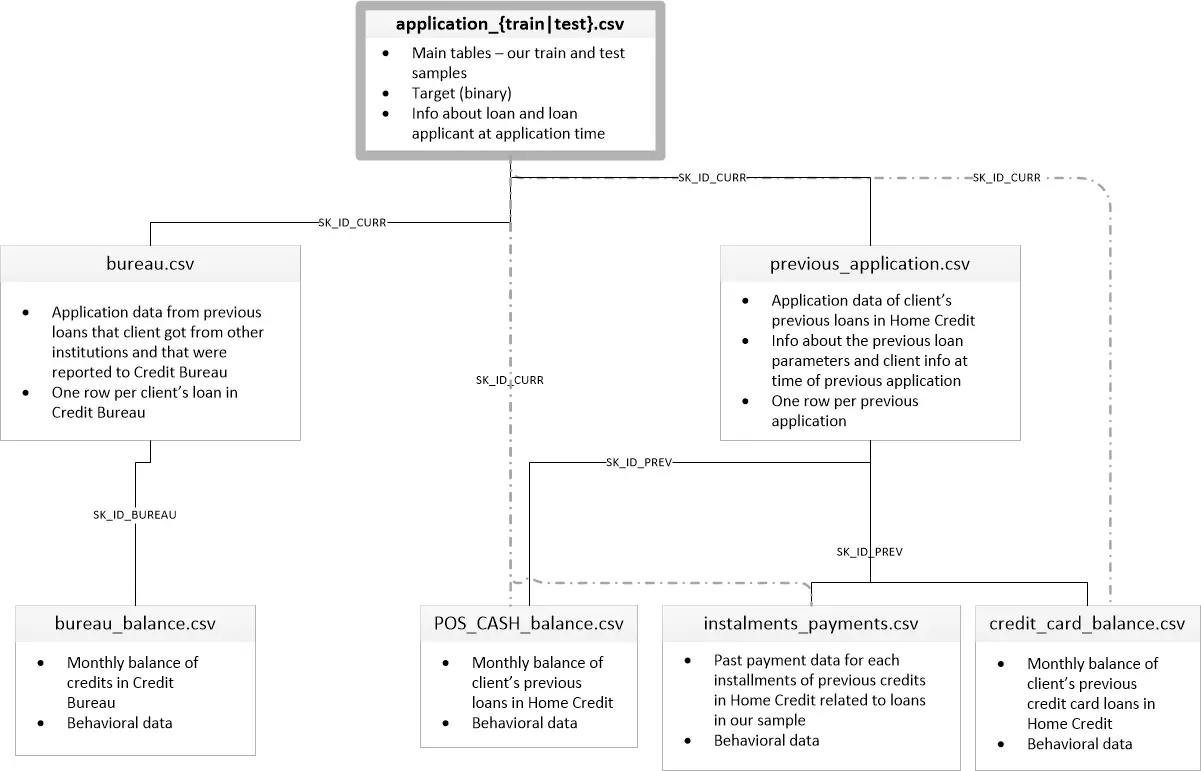

</div>

In [ ]:
REPORTS_DIR = '../data/eda_reports/'
RAW_DATA_DIR = '../data/raw/'
def get_eda_report(filename, show_report=False):
    os.makedirs(RAW_DATA_DIR, exist_ok=True)
    os.makedirs(REPORTS_DIR, exist_ok=True)
    df = pd.read_csv(RAW_DATA_DIR + filename)
    profile = ProfileReport(df, title=filename + " Report", minimal=True)
    profile.to_file(REPORTS_DIR + filename + ".html")
    if show_report: profile.to_notebook_iframe()

#### **application_{train|test}.csv**

Это основная таблица, разбитая на два файла: «Train» (с TARGET) и «Test» (без TARGET).

Статические данные по всем заявкам. Одна строка соответствует одному кредиту в нашей выборке данных.

#### **bureau.csv**

Все предыдущие кредиты клиента, предоставленные другими финансовыми учреждениями, которые были переданы в Бюро кредитной истории (для клиентов, имеющих кредит в нашей выборке).

Для каждого кредита в нашей выборке количество строк соответствует количеству кредитов, которые клиент имел в Бюро кредитной истории до даты подачи заявки.

#### **bureau_balance.csv**

Ежемесячные остатки по предыдущим кредитам в Бюро кредитной истории.

В этой таблице по одной строке на каждый месяц истории каждого предыдущего кредита, о котором было сообщено в Кредитное бюро, — т. е. в таблице столько строк, сколько (#кредитов в выборке * количество соответствующих предыдущих кредитов * количество месяцев, за которые у нас есть наблюдаемая история по предыдущим кредитам).

#### **POS_CASH_balance.csv**

Снимки ежемесячных остатков по предыдущим POS-кредитам (кредитам в точках продаж) и денежным кредитам, которые заявитель имел в Home Credit.

В этой таблице по одной строке на каждый месяц истории каждого предыдущего кредита в Home Credit (потребительские кредиты и кредиты наличными), связанного с кредитами в нашей выборке, т.е. таблица содержит (#кредитов в выборке * количество соответствующих предыдущих кредитов * количество месяцев, за которые имеется история по предыдущим кредитам) строк.

#### **credit_card_balance.csv**

Ежемесячные отчеты по остаткам на предыдущих кредитных картах, выданных заявителю компанией «Home Credit».

В этой таблице по одной строке на каждый месяц истории каждого предыдущего кредита в Home Credit (потребительский кредит и денежные ссуды), связанного с кредитами в нашей выборке, т. е. таблица содержит (#кредитов в выборке * количество соответствующих предыдущих кредитных карт * количество месяцев, за которые имеются данные по предыдущей кредитной карте) строк.

#### **previous_application.csv**

Все предыдущие заявки на кредиты Home Credit от клиентов, имеющих кредиты в нашей выборке.

В таблице по одной строке на каждую предыдущую заявку, связанную с кредитами в нашей выборке данных.

#### **installments_payments.csv**

История погашения ранее выданных кредитов в Home Credit, связанных с кредитами в нашей выборке.

Имеется а) одна строка для каждого произведенного платежа плюс б) по одной строке для каждого пропущенного платежа.

Одна строка соответствует одному платежу по одному взносу ИЛИ одному взносу, соответствующему одному платежу по одному предыдущему кредиту Home Credit, связанному с кредитами в нашей выборке.

### HTML отчеты с EDA по каждой таблице

In [ ]:
# files = [f for f in os.listdir(RAW_DATA_DIR) if f.endswith('.csv') and f != 'HomeCredit_columns_description.csv' and f != 'sample_submission.csv']

# for filename in files:
#     print(f"Обработка файла {filename}...")
#     get_eda_report(filename)
#     print(f"Завершена обработка файла {filename}")
# print(f"Обработка всех файлов завершена!")

---

# Анализ таблиц

---

## **1. application_train.csv**

#### **Сильный дисбаланс классов в переменной TARGET.**

Модель видит около 92% "хороших" клиентов и только около 8% "плохих" (допустивших дефолт). Перед нами задача с **несбалансированными классами**.

**Что с этим можно сделать:**

1. При валидации обязательно стоит использовать StratifiedKFold, чтобы соотношение классов сохранялось в каждом фолде.
2. Оценивать модель только по метрике ROC-AUC.
3. Использовать встроенные в алгоритмы параметры балансировки весов (например, scale_pos_weight в XGBoost или class_weight в CatBoost/Random Forest).

<div style="max-width: 550px;">

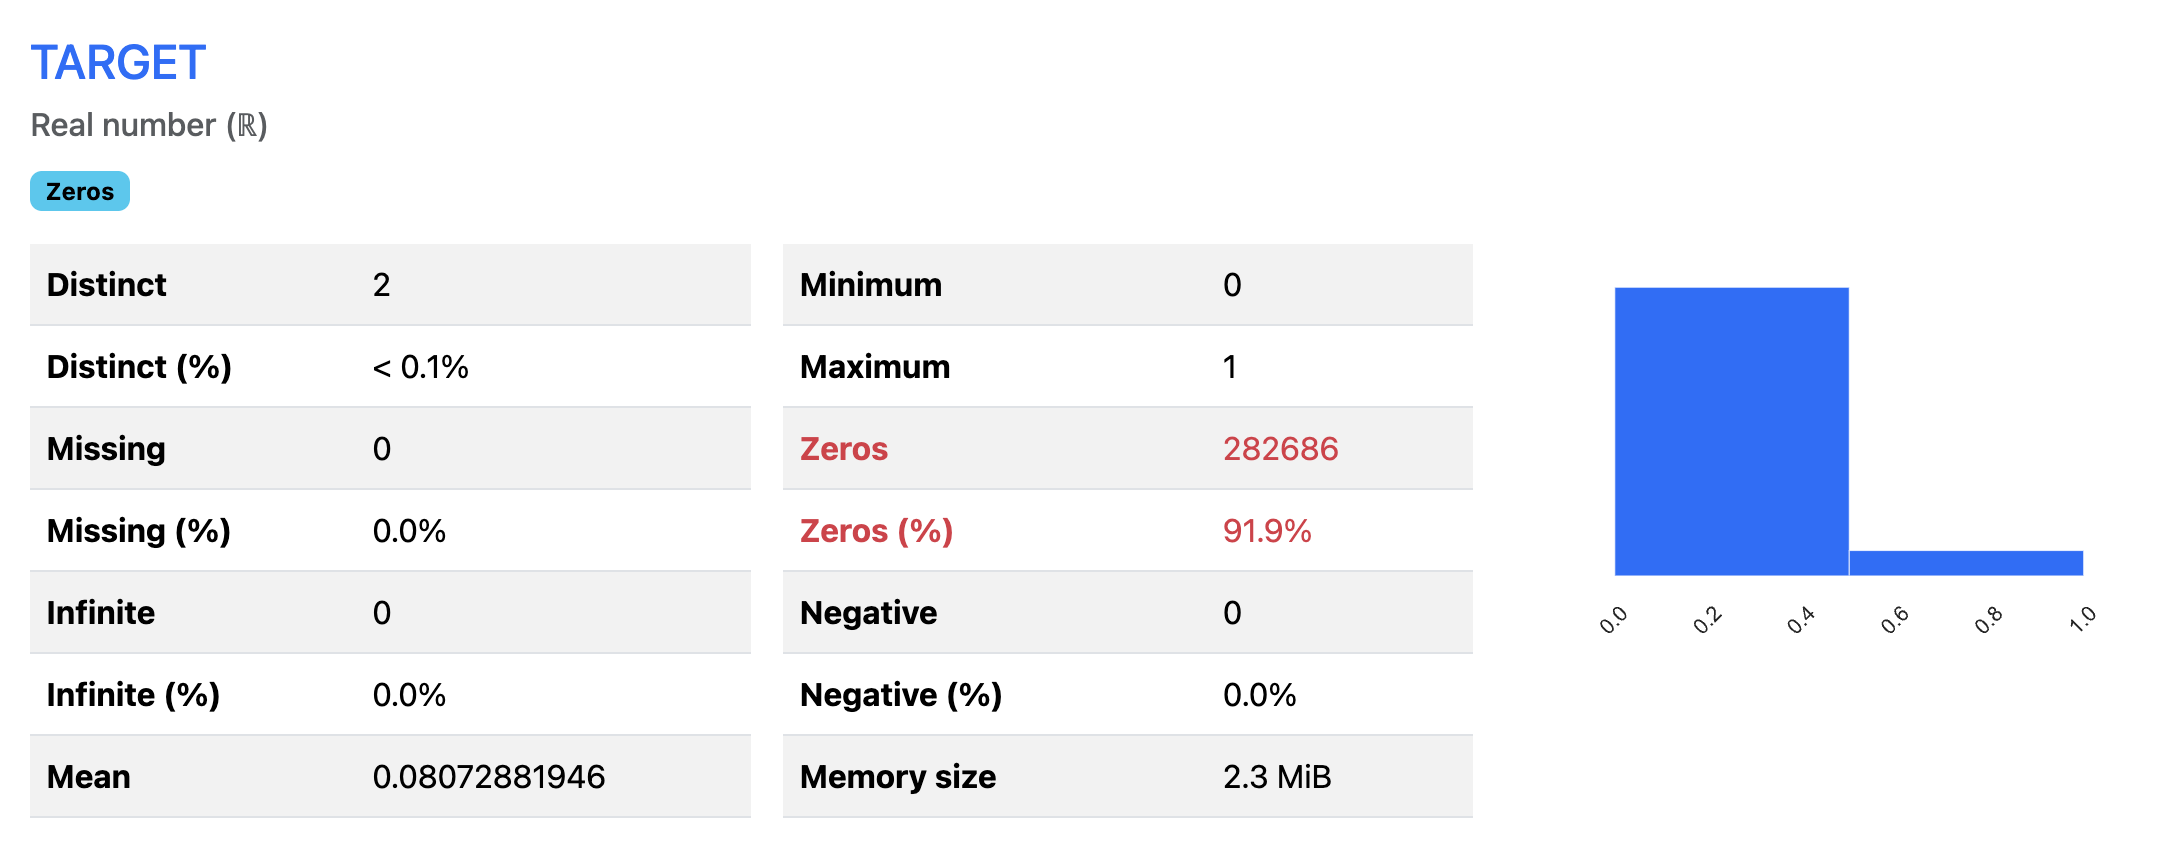

</div>

#### **Огромное количество пропусков.**

<div style="max-width: 300px;">

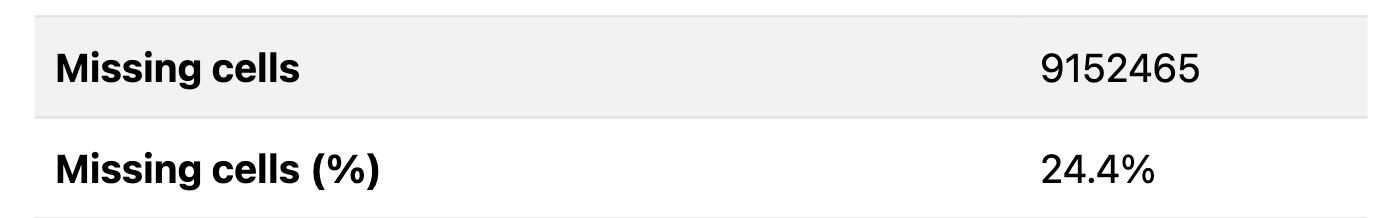

</div>

У огромного количества колонок пропущено более 50% данных. В основном это касается данных о недвижимости заемщика (APARTMENTS_AVG, YEARS_BEGINEXPLUATATION_AVG и т.д.) и внешних скоринговых баллов (EXT_SOURCE_1)

**Что с этим можно сделать:**

Не стоит удалять эти столбцы!

1. При использовании бустингов (LightGBM, XGBoost, CatBoost), просто оставляем пропуски как NaN - алгоритмы сами найдут в них паттерны.

2. Можно создать бинарные флаги пропусков (например, EXT_SOURCE_1_IS_MISSING), где 1 — данных нет, 0 — данные есть. В кредитном скоринге сам факт непредоставления информации часто говорит о риске.

3. Признаки недвижимости можно сагрегировать (например, посчитать среднее количество комнат или общую площадь) вместо использования 20 похожих столбцов.


#### **Колонки со skewed распределением.**

В основном это колонки типа FLAG_DOCUMENT_N, где N - номер документа, который предоставил/не предоставил клиент.
В основном значения 0.

Посмотрим на примере FLAG_DOCUMENT_21:

FLAG_DOCUMENT_21 is highly skewed (γ1 = 54.61293914)

Это бинарный признак. Почти все значения = 0, очень редки 1.

<div style="max-width: 600px;">

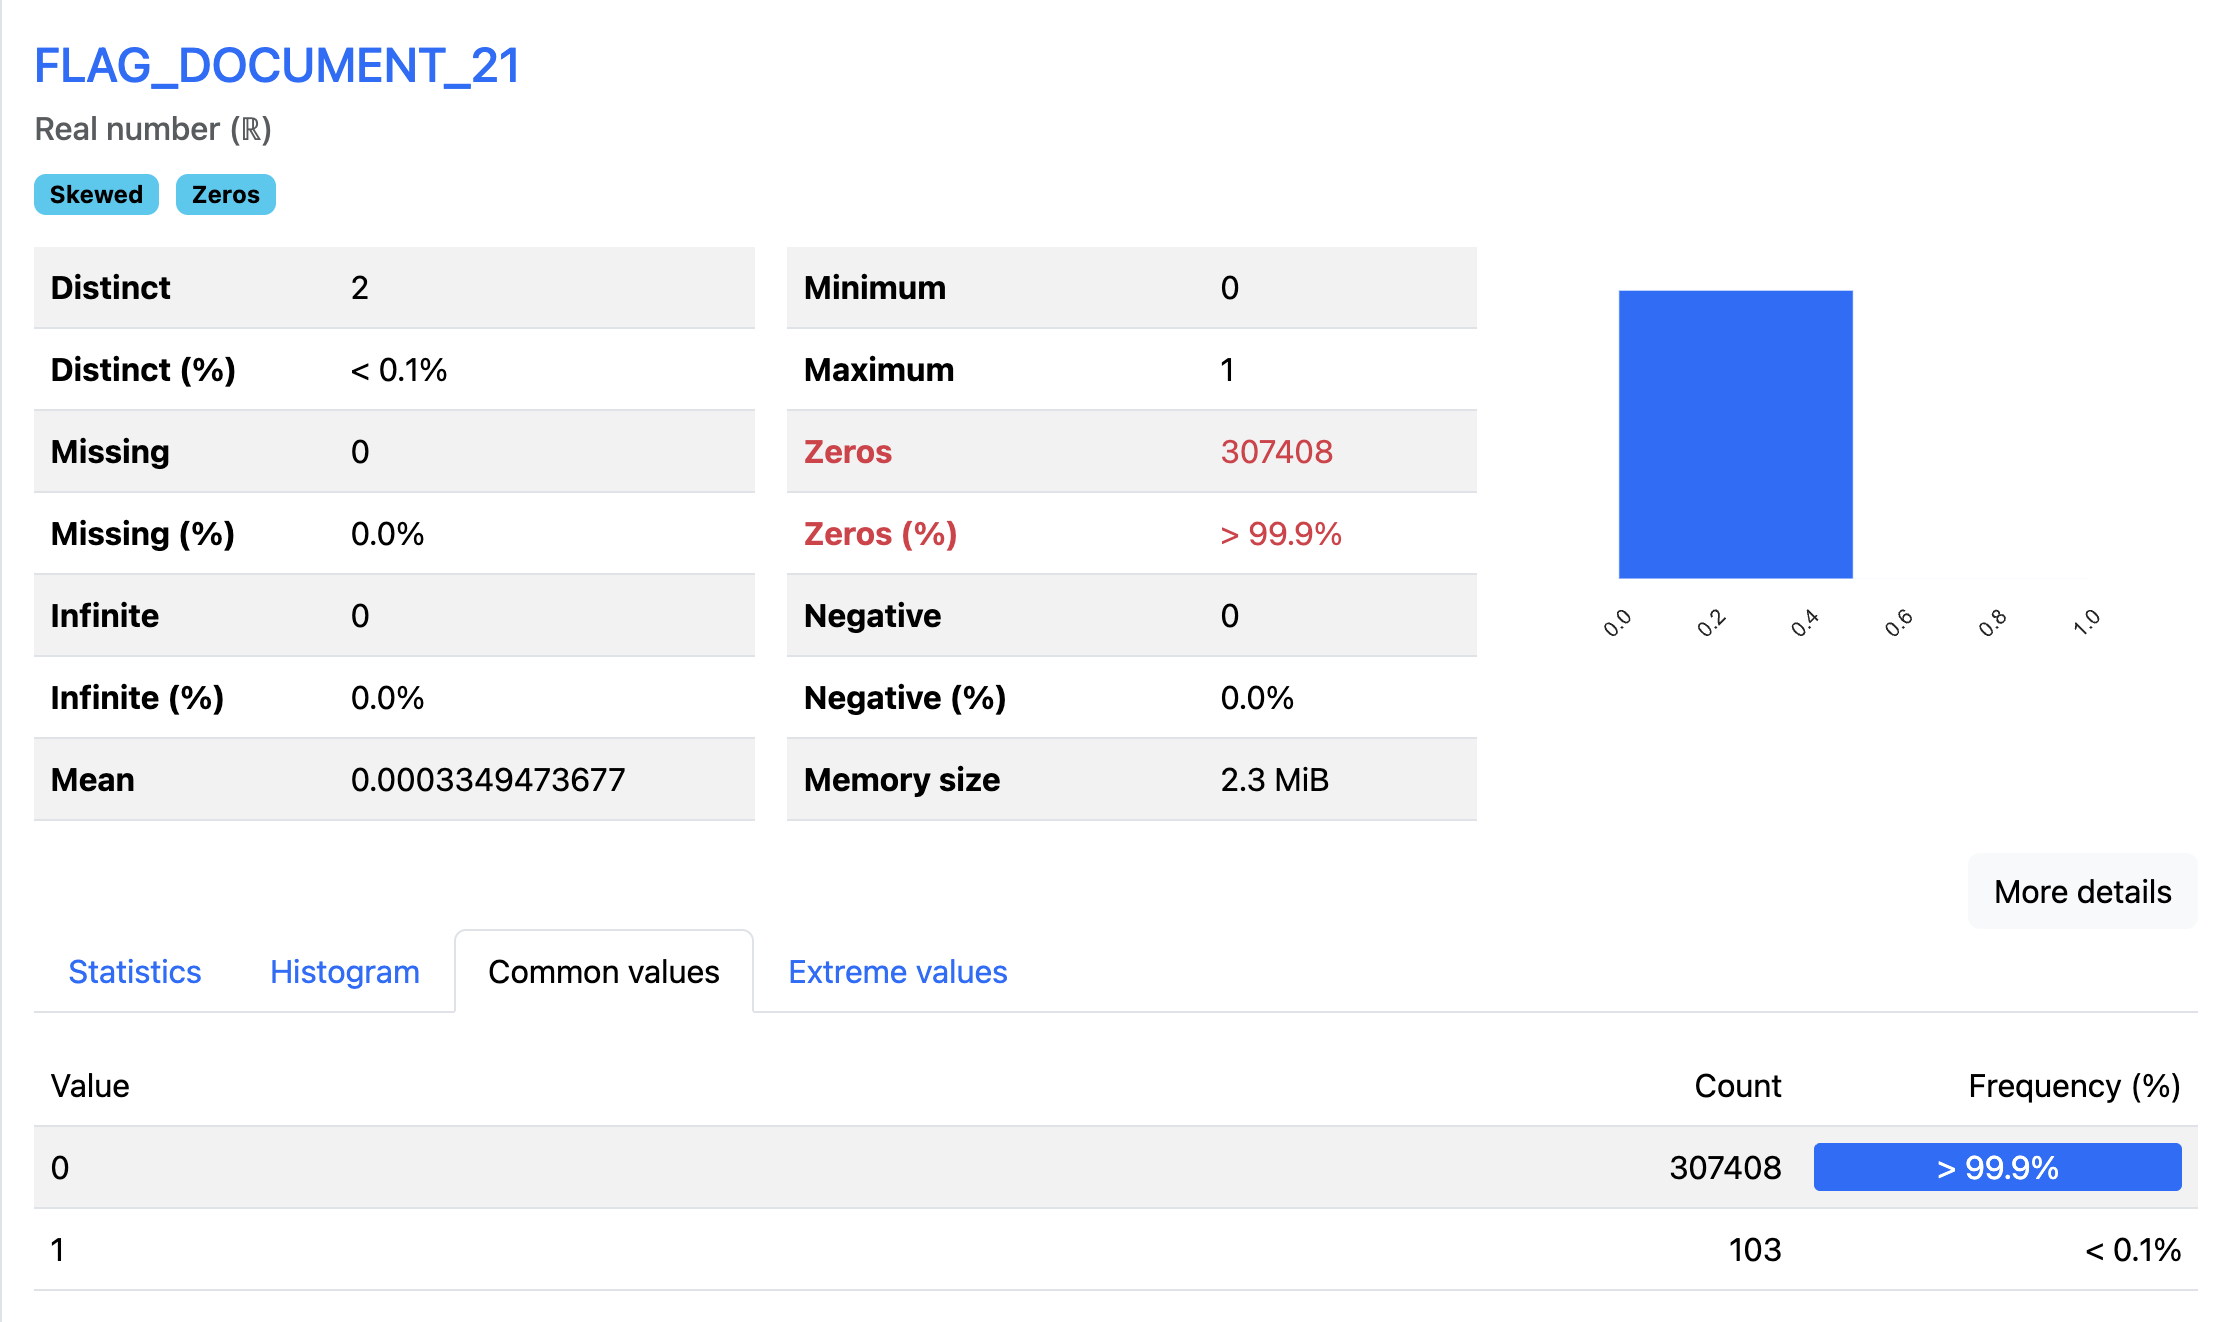

</div>

Также есть большое кол-во других столбцов, у которых большая часть значений - 0

#### **Аномалии в признаке DAYS_EMPLOYED (Трудовой стаж).**

<div style="max-width: 600px;">

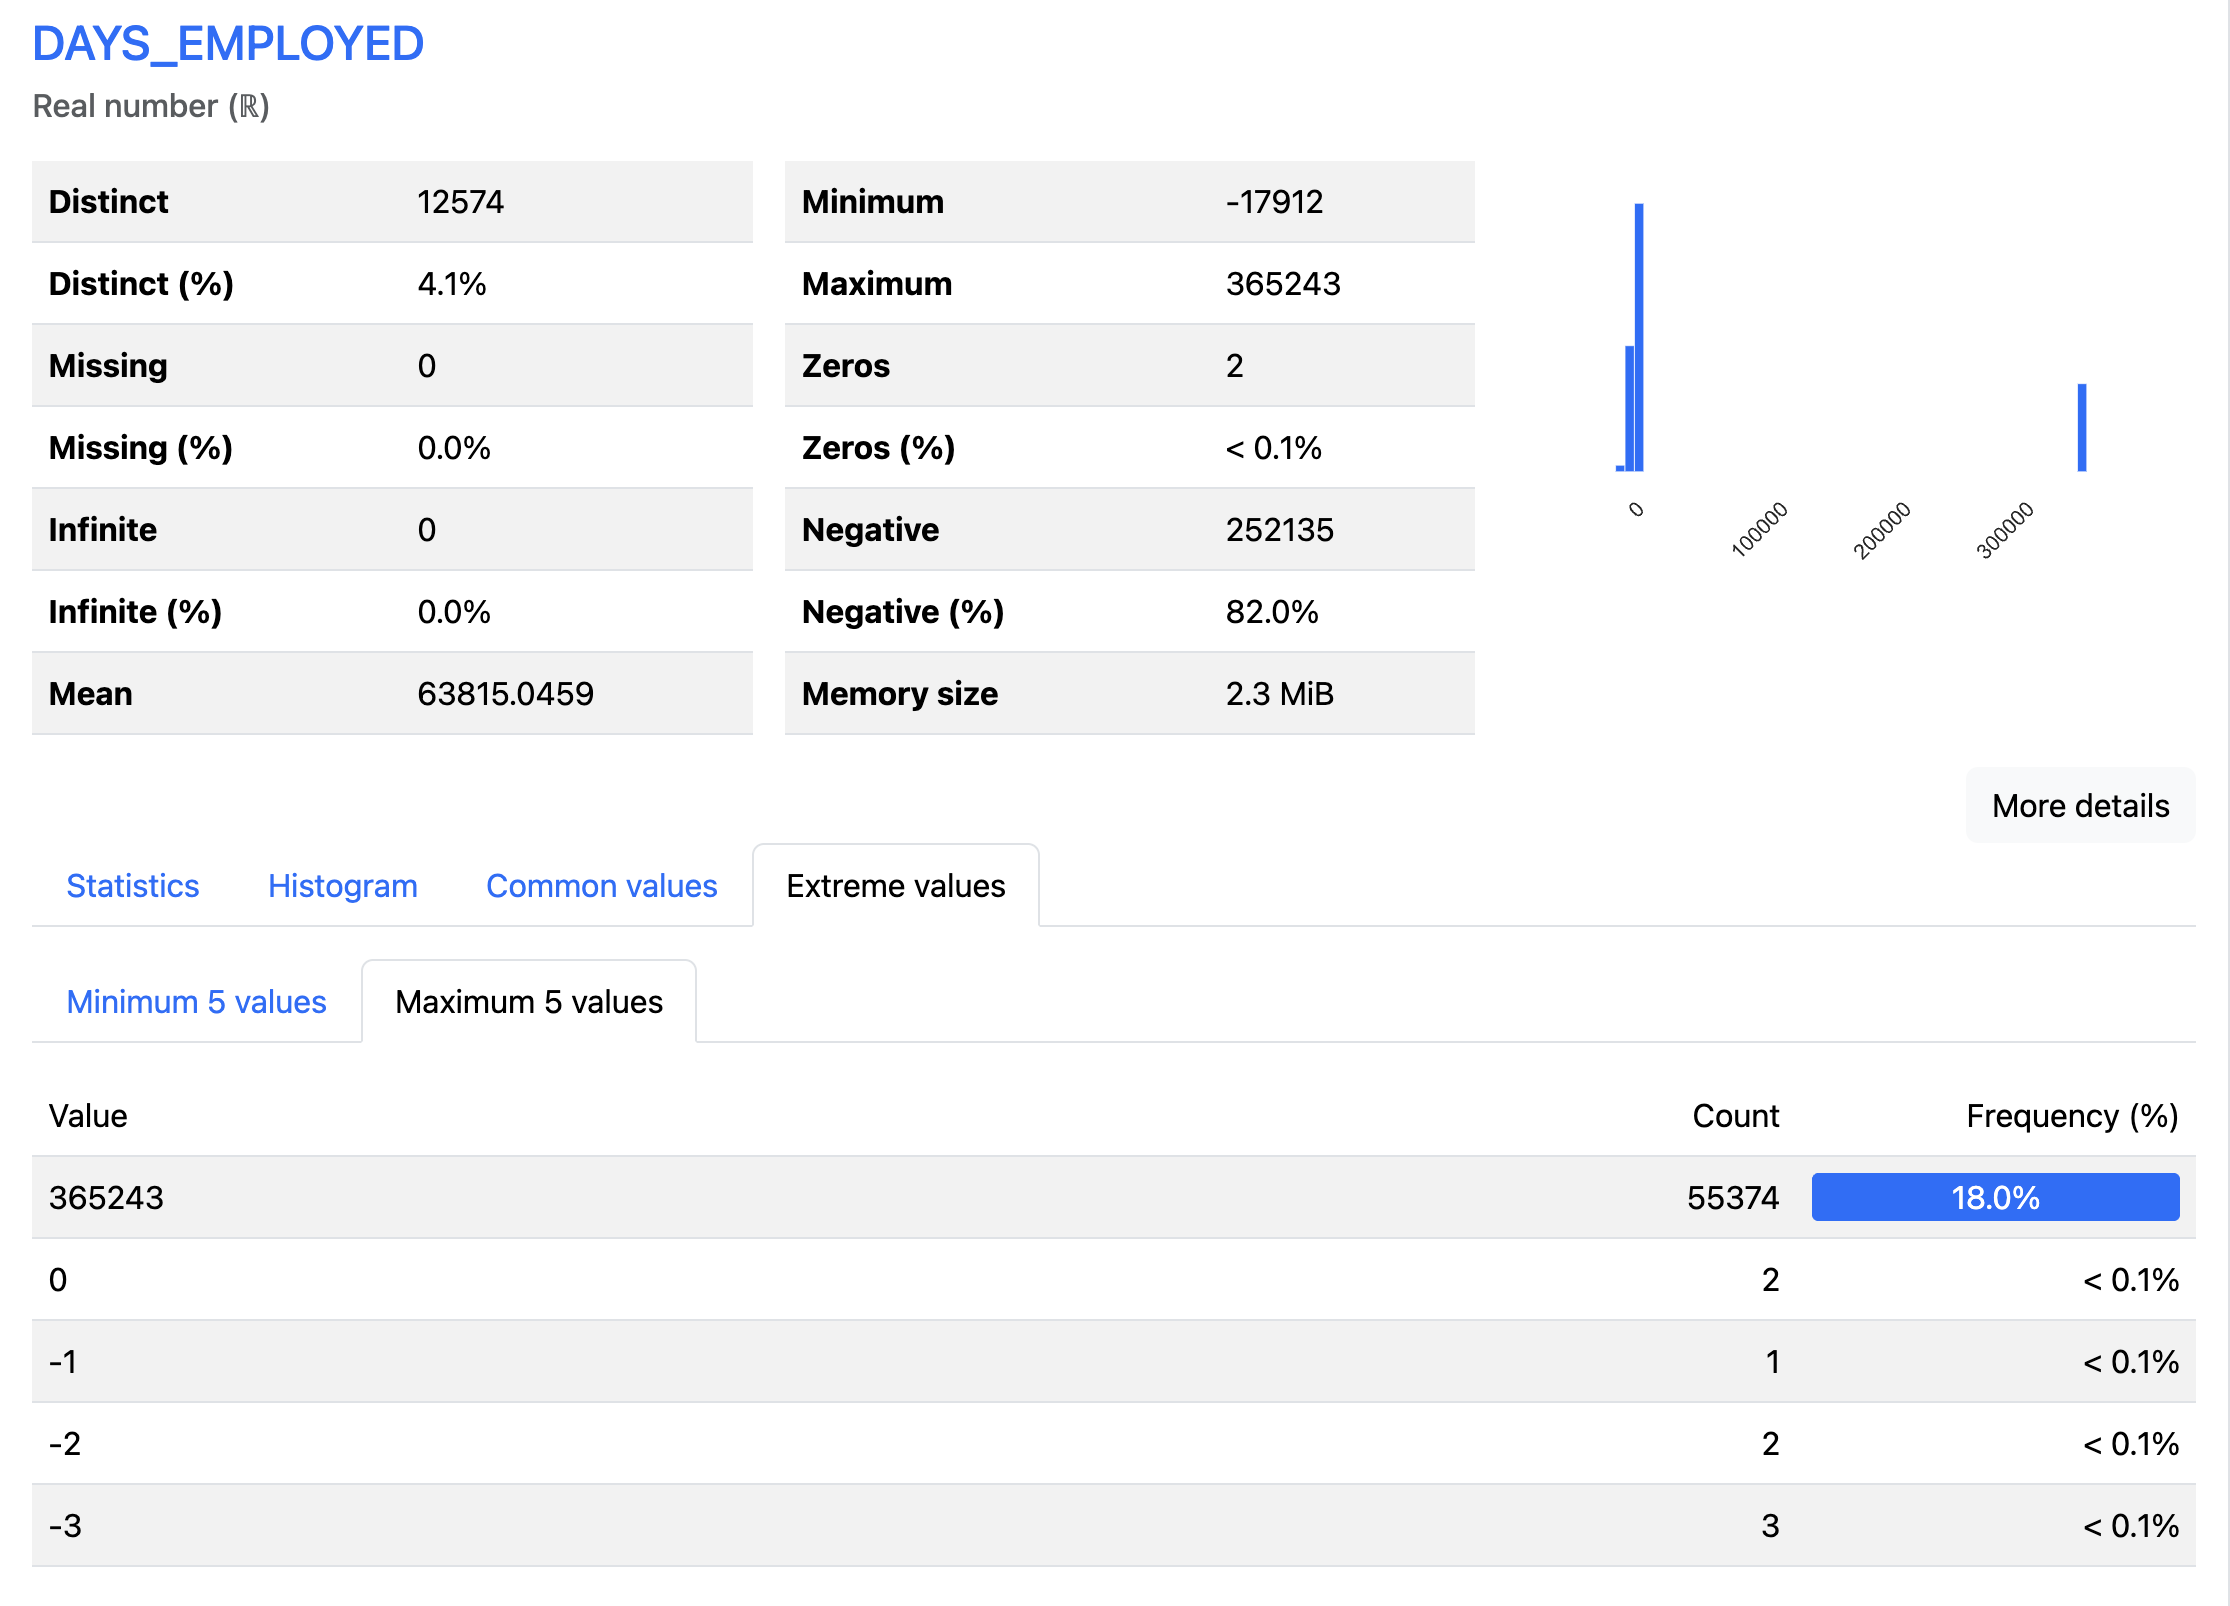

</div>

Максимальное значение 365243. Это 1000 лет! Очевидно, это техническая заглушка.

**Что с этим можно сделать:**

1. Создать бинарный признак DAYS_EMPLOYED_ANOMALOUS (1 — если значение равно 365243, иначе 0).
2. В оригинальном столбце заменить это число на NaN (если модель умеет с ними работать) или на 0. Это число чаще всего встречается у пенсионеров и безработных.

### Label Encoding и One-Hot-Encoding

Для любой категориальной переменной (`dtype == object`) с двумя уникальными категориями будем использовать Label Encoding, а для любой категориальной переменной с более чем двумя уникальными категориями — One-Hot Encoding.

In [ ]:
le = LabelEncoder()
le_count = 0

for col in df_train:
    if df_train[col].dtype == 'object':
        # Если 2 или меньше уникальных категорий:
        if len(list(df_train[col].unique())) <= 2:
            le.fit(df_train[col])
            df_train[col] = le.transform(df_train[col])
            df_test[col] = le.transform(df_test[col])
        
            le_count += 1
            
print(f'Количество столбцов, на которых применен Label Encoding: {le_count}')

In [ ]:
# one-hot encoding для категориальных фичей
df_train = pd.get_dummies(df_train)
df_test = pd.get_dummies(df_test)

print('Trai shape: ', df_train.shape)
print('Test shape: ', df_test.shape)

### Выравнивание обучающих и тестовых данных

В обучающих и тестовых данных должны присутствовать одинаковые признаки, поэтому делаем alignment

In [ ]:
train_labels = df_train['TARGET']

# Выраниванием train и test данные, оставляем только те столбцы, которые присутствуют в обоих df
df_train, df_test = df_train.align(df_test, join = 'inner', axis = 1)

# Добавляем таргет обратно в train
df_train['TARGET'] = train_labels

print('Train shape: ', df_train.shape)
print('Test shape: ', df_test.shape)

### Аномалии в данных

Числа в столбце `DAYS_BIRTH` являются отрицательными, поскольку они записываются относительно текущей заявки на кредит

In [ ]:
(df_train['DAYS_BIRTH'] / -365).describe()

In [ ]:
df_train['DAYS_EMPLOYED'].describe()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

df_train['DAYS_EMPLOYED'].plot.hist(bins=50, ax=ax, edgecolor='black')

ax.set_title('Распределение кол-ва дней занятости')
ax.set_xlabel('Кол-во дней занятости')
ax.set_ylabel('Частота')
plt.show()

Заполним аномальные значения значением NaN, а затем создадим новый столбец с булевыми значениями, указывающий, было ли значение аномальным.

In [ ]:
df_train['DAYS_EMPLOYED_ANOM'] = df_train['DAYS_EMPLOYED'].eq(365243)

df_train['DAYS_EMPLOYED'] = df_train['DAYS_EMPLOYED'].replace(365243, np.nan)

fig, ax = plt.subplots(figsize=(8, 5))

df_train['DAYS_EMPLOYED'].plot.hist(bins=50, ax=ax, edgecolor='black')

ax.set_title('Распределение кол-ва дней занятости')
ax.set_xlabel('Кол-во дней занятости')
ax.set_ylabel('Частота')
plt.show()

Сделаем то же самое и для тестовых данных:

In [ ]:
df_test['DAYS_EMPLOYED_ANOM'] = df_test['DAYS_EMPLOYED'].eq(365243)

df_test['DAYS_EMPLOYED'] = df_test['DAYS_EMPLOYED'].replace(365243, np.nan)

n_anom = df_test['DAYS_EMPLOYED_ANOM'].sum()
n_total = len(df_test)

print(f'В тестовых данных найдено {n_anom} аномалий из {n_total} записей')

### Корелляции с целевой переменной
 
Найдем корреляции между признаками и целевой переменной.

Интерпретация:
* 0,00–0,19 «очень слабая»
* 0,20–0,39 «слабая»
* 0,40–0,59 «умеренная»
* 0,60–0,79 «сильная»
* 0,80–1,0 «очень сильная»

In [ ]:
correlations = df_train.corr()['TARGET'].sort_values()

print('Наибольшие по модулю положительные корреляции:\n', correlations.tail(15))
print('\nНаибольшие по модулю отрицательные корреляции:\n', correlations.head(15))

Давайте рассмотрим некоторые из наиболее значимых корреляций:

`DAYS_BIRTH` демонстрирует самую высокую положительную корреляцию.

`DAYS_BIRTH` — это возраст клиента в днях на момент оформления кредита, выраженный в отрицательных числах. Корреляция положительная, но значение этой характеристики на самом деле отрицательное, что означает: **чем старше становится клиент, тем меньше вероятность того, что он не выполнит свои обязательства по кредиту** (т. е. цель == 0).

In [ ]:
df_train['DAYS_BIRTH'] = abs(df_train['DAYS_BIRTH']) # Возьмем абсолютное значение характеристики -> корреляция станет отрицательной
df_train['DAYS_BIRTH'].corr(df_train['TARGET'])

С увеличением возраста клиента наблюдается отрицательная линейная зависимость от целевого показателя, то есть чем старше клиенты, тем чаще они погашают кредиты в срок.

Давайте рассмотрим эту переменную. Для начала построим гистограмму возраста. Ось x возьмем в годах, чтобы график был более понятным.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

# гистограмма распределения возраста клиентов
ax.hist(df_train['DAYS_BIRTH'] / 365, bins=25, edgecolor='black')

ax.set_title('Распределение возраста клиентов')
ax.set_xlabel('Возраст (лет)')
ax.set_ylabel('Количество клиентов')
plt.show()

Само по себе распределение возрастов не говорит нам ничего особенного, кроме того, что выбросов нет, поскольку все возрасты находятся в разумных ограничениях.

Рассмотрим эту зависимость с другой стороны: средний показатель невыплаты кредитов по возрастным группам. 

Чтобы построить этот график, сначала мы разбиваем возрастную категорию на интервалы по 5 лет. Затем для каждого интервала мы вычисляем среднее значение целевой переменной, которое показывает нам долю непогашенных кредитов в каждой возрастной категории.

In [ ]:
age_data = df_train[['TARGET', 'DAYS_BIRTH']].copy()
age_data['YEARS_BIRTH'] = age_data['DAYS_BIRTH'] / 365

age_data['YEARS_BINNED'] = pd.cut(age_data['YEARS_BIRTH'], bins = np.linspace(20, 70, num = 11)) # делаем бинаризацию
age_data.head(10)

In [ ]:
age_groups  = age_data.groupby('YEARS_BINNED', observed=True).mean() # группируем по бину и считаем средние
age_groups

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(age_groups.index.astype(str), 100 * age_groups['TARGET'])

ax.set_title('Доля невозврата кредита по возрастным группам')
ax.set_xlabel('Возрастная группа (лет)')
ax.set_ylabel('Невозврат кредита (%)')

ax.tick_params(axis='x', rotation=75)
plt.show()

У молодых заемщиков вероятность невыполнения обязательств по кредиту выше! Доля невыполнения обязательств превышает 10 % для трех самых молодых возрастных групп и составляет менее 5 % для самой старшей возрастной группы.

### Внешние источники (EXT_SOURCES)

Три переменные, имеющие наиболее сильную отрицательную корреляцию с целевой переменной, — это `EXT_SOURCE_1`, `EXT_SOURCE_2` и `EXT_SOURCE_3`.
Согласно документации, эти признаки представляют собой «нормализованный балл из внешнего источника данных».

Посчитаем корреляции `EXT_SOURCE` с целевой переменной и друг с другом.

In [ ]:
ext_data = df_train[['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH']]
ext_data_corrs = ext_data.corr()
ext_data_corrs

In [ ]:
plt.figure(figsize = (8, 5))

sns.heatmap(ext_data_corrs, vmin = -0.25, annot = True, vmax = 0.6)
plt.title('Тепловая карта корреляций')
plt.show()

Все три признака `EXT_SOURCE` имеют отрицательную корреляцию с целевой переменной, что указывает на то, что по мере увеличения значения `EXT_SOURCE` вероятность погашения кредита клиентом возрастает. Мы также видим, что `DAYS_BIRTH` положительно коррелирует с `EXT_SOURCE_1`, что указывает на то, что одним из факторов, влияющих на этот показатель, возможно, является возраст клиента.

Далее мы можем рассмотреть распределение каждой из этих характеристик, окрашенное в зависимости от значения целевой переменной. Это позволит нам визуализировать влияние данной переменной на целевую переменную.

In [ ]:
sources = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

fig, axes = plt.subplots(
    nrows=len(sources),
    ncols=1,
    figsize=(10, 8),
    sharex=False
)

for ax, source in zip(axes, sources):

    # распределение для клиентов, вернувших кредит
    sns.kdeplot(
        data=df_train.loc[df_train['TARGET'] == 0],
        x=source,
        label='TARGET = 0 (кредит возвращён)',
        ax=ax
    )

    # распределение для клиентов с дефолтом
    sns.kdeplot(
        data=df_train.loc[df_train['TARGET'] == 1],
        x=source,
        label='TARGET = 1 (дефолт)',
        ax=ax
    )

    ax.set_title(f'Распределение {source} по значению TARGET')
    ax.set_xlabel(source)
    ax.set_ylabel('Плотность')
    ax.legend()

fig.tight_layout(pad=1.5)

plt.show()

`EXT_SOURCE_3` демонстрирует наибольшую разницу между значениями целевой переменной. Эта характеристика имеет некоторую связь с вероятностью того, что заявитель погасит кредит. Эта связь не очень сильная, но может помочь.

---

## **2. bureau.csv (История из внешних кредитных бюро)**

#### **Многочисленные пропуски в лимитах и суммах задолженностей.**

<div style="max-width: 300px;">

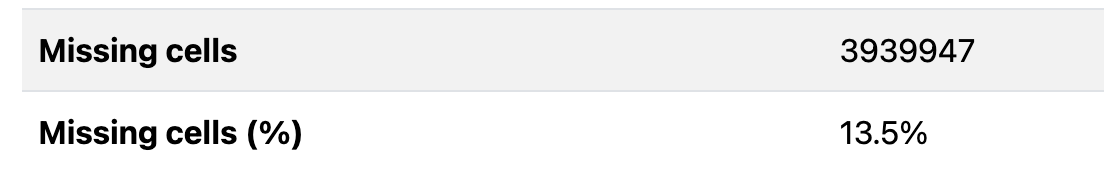

</div>


Например, в признаках AMT_CREDIT_SUM_LIMIT или AMT_CREDIT_MAX_OVERDUE.

<div style="max-width: 600px;">

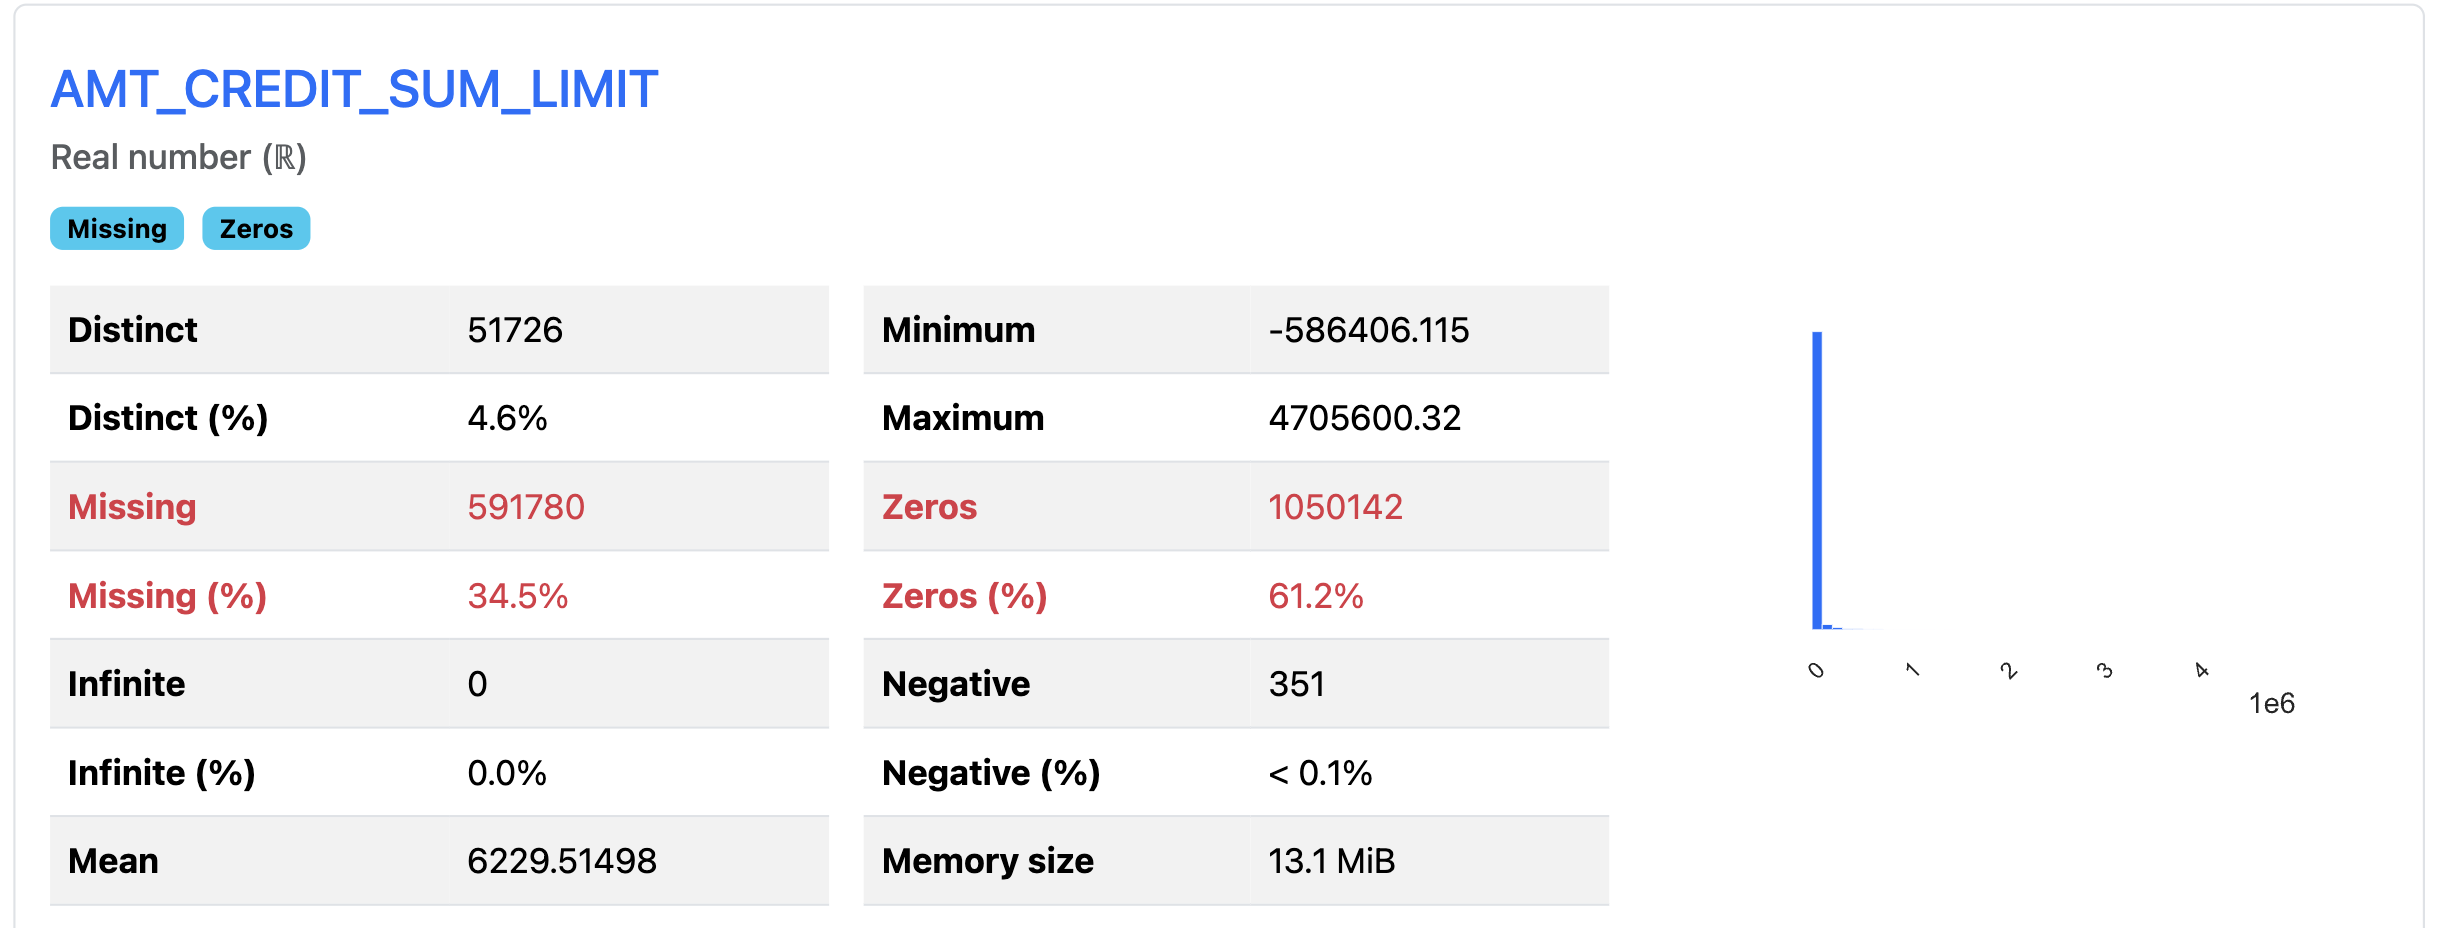

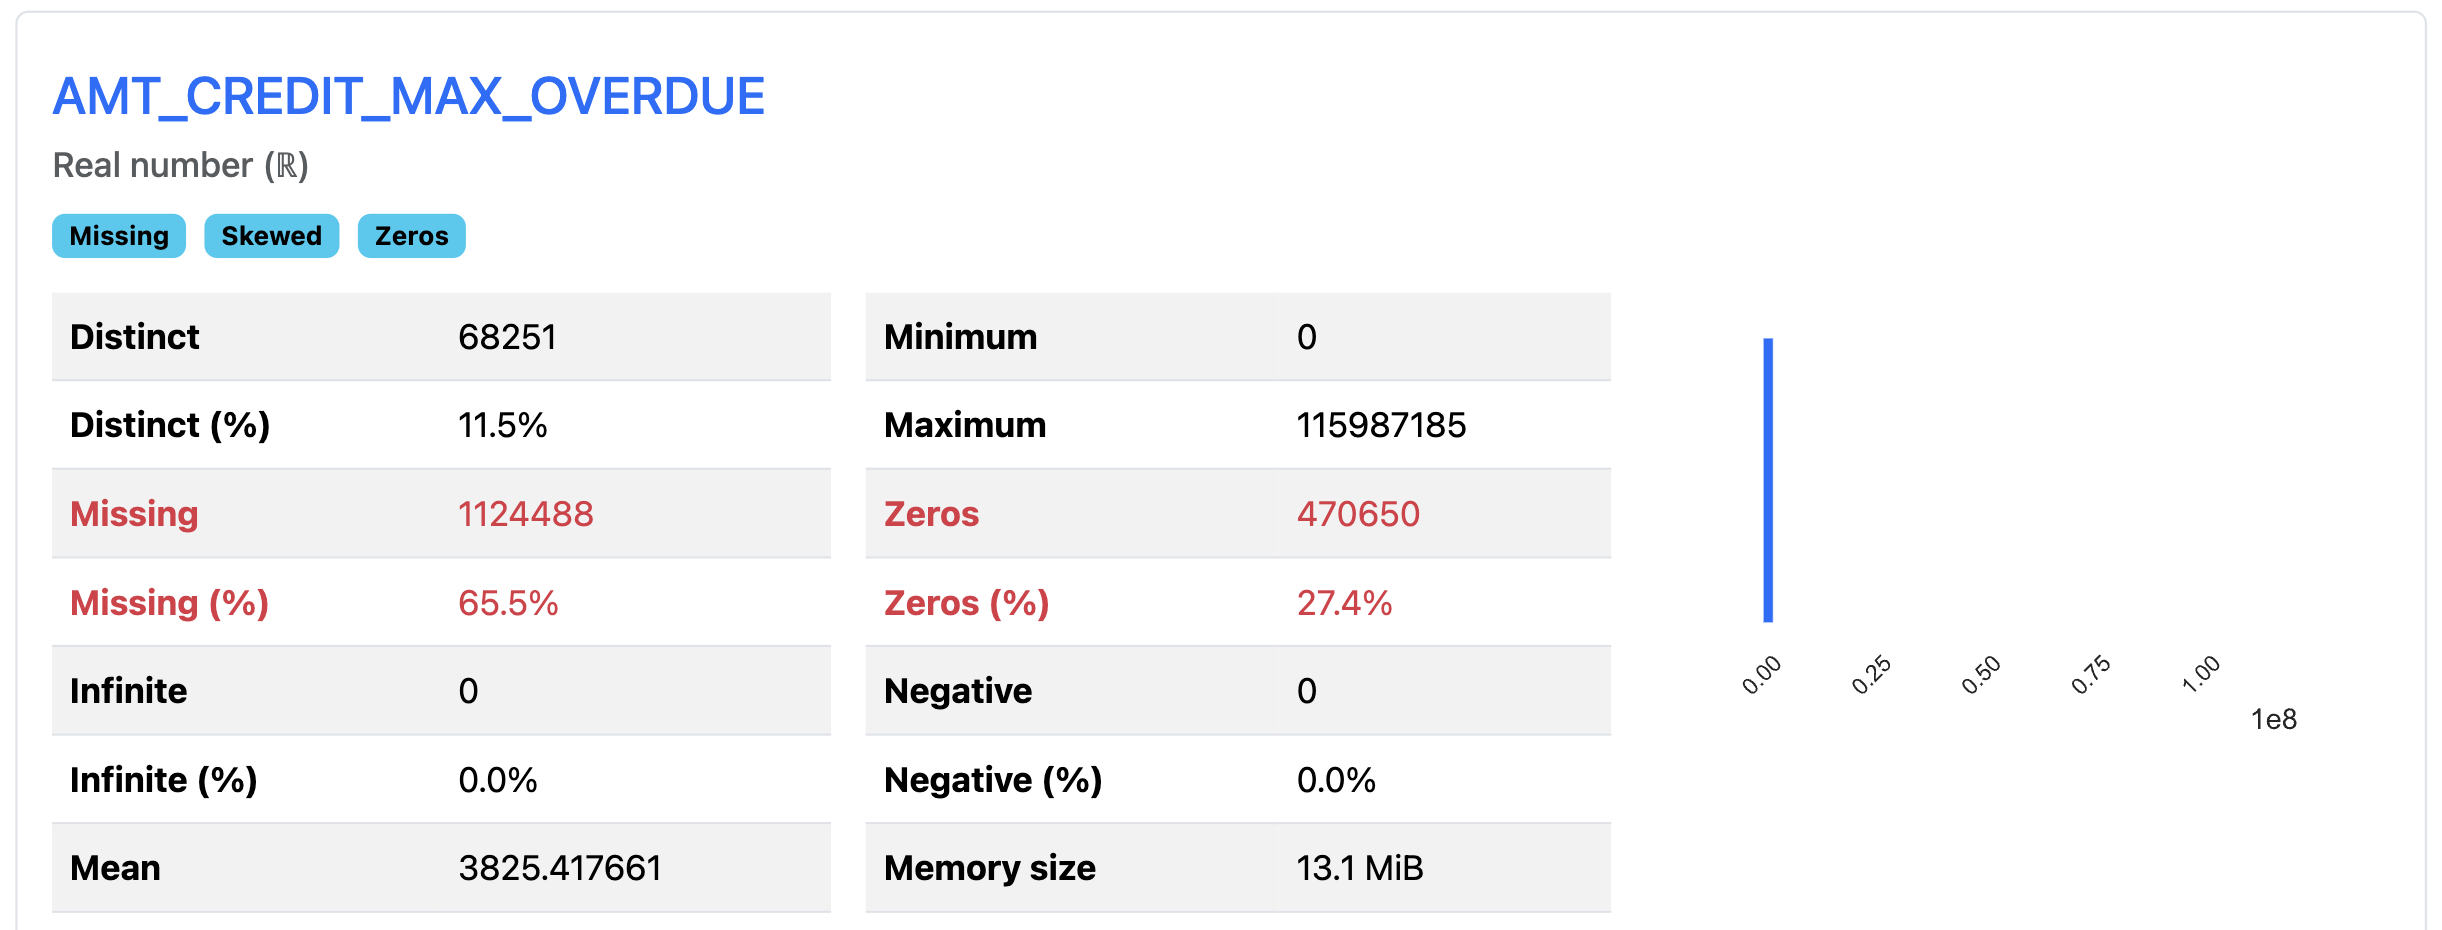

</div>

**Что можно сделать:**
1. Пропуски в кредитном лимите (AMT_CREDIT_SUM_LIMIT) чаще всего означают, что это был обычный кредит, а не кредитная карта (где лимит возобновляемый). Их можно безопасно заполнить нулями.
2. Пропуски в максимальной сумме просрочки (MAX_OVERDUE) обычно означают, что просрочек не было — заполни нулями.

#### **Множественность записей (Связь 1-ко-многим).**

На одного клиента (SK_ID_CURR) в таблице приходится несколько строк (по числу прошлых кредитов в других банках).
Эту таблицу нельзя использовать в чистом виде. Ее нужно сагрегировать по SK_ID_CURR.

**Что можно сделать:**
1. Создать новые признаки: общее количество кредитов заемщика, количество активных кредитов, средняя сумма долга, максимальная просрочка.
2. После агрегации объединить получившуюся таблицу с application_train.

---

## **3. previous_application.csv (Прошлые заявки в Home Credit)**

#### **Категориальные переменные с огромным числом редких категорий.**

Например, в PRODUCT_COMBINATION или NAME_TYPE_SUITE.

<div style="max-width: 650px;">

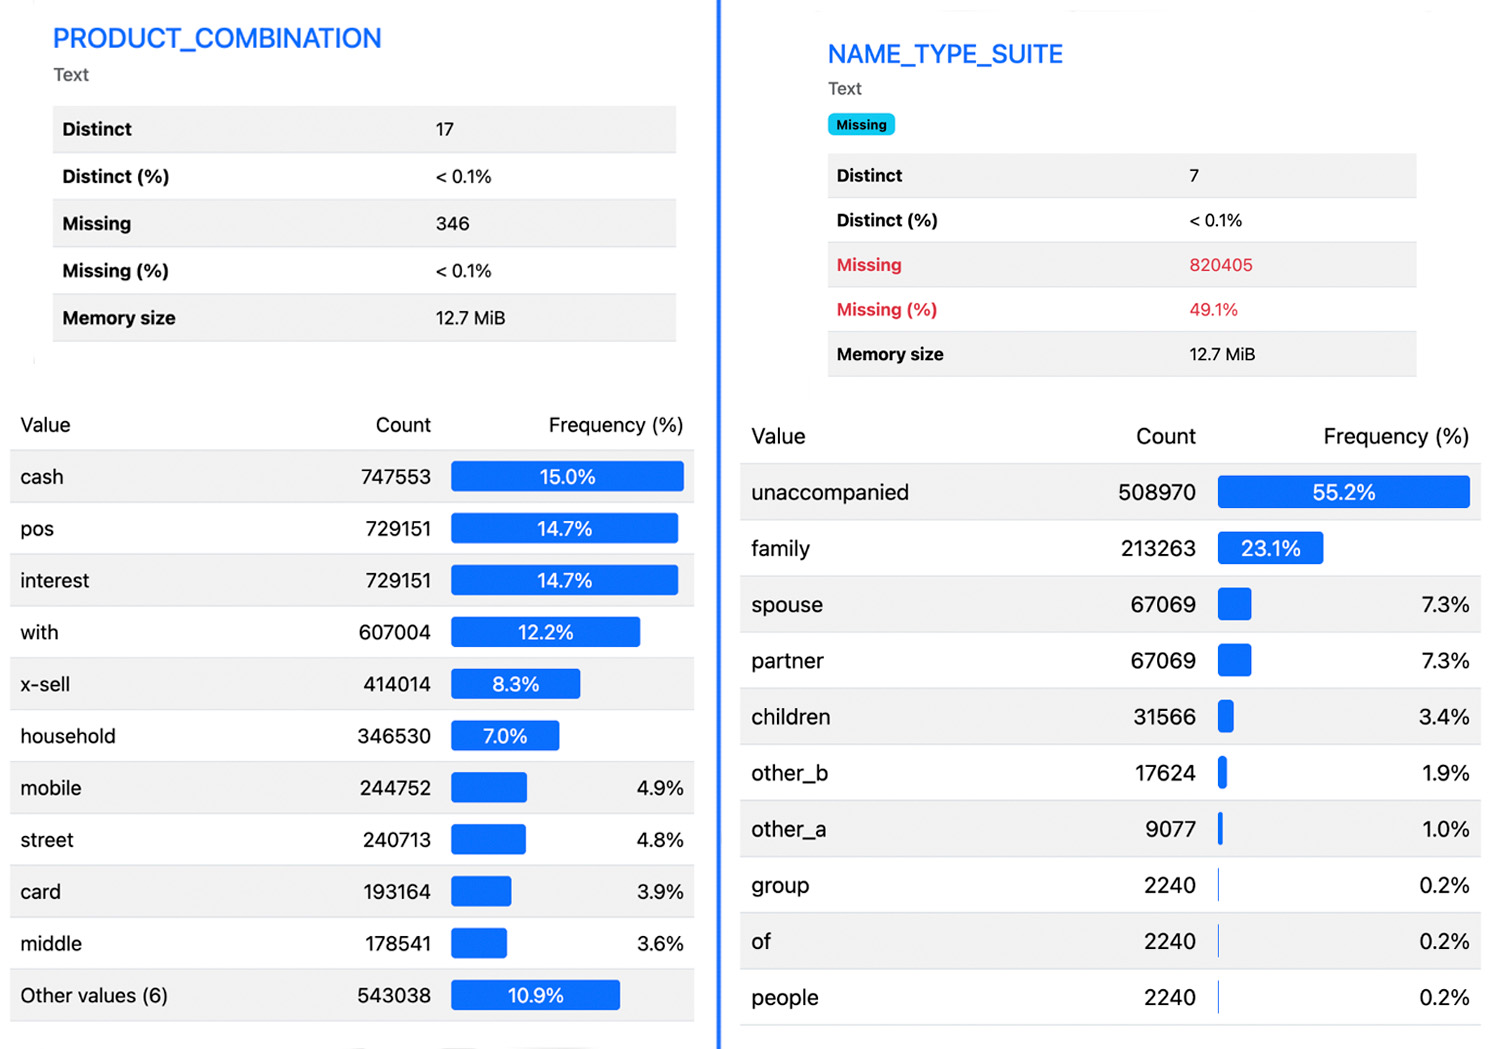

</div>

**Что можно сделать:**

1. Сгруппировать все редкие категории (например, те, что встречаются менее чем в 1% случаев) в одну общую категорию "Other".
2. Для работы с высококардинальными категориями использовать Target Encoding (кодирование средним значением целевой переменной), но делать это строго внутри фолдов кросс-валидации, чтобы избежать переобучения.

#### **Аномальные даты (365243).**

Они встречаются в полях DAYS_FIRST_DRAWING, DAYS_FIRST_DUE и т.д.

<div style="max-width: 550px;">

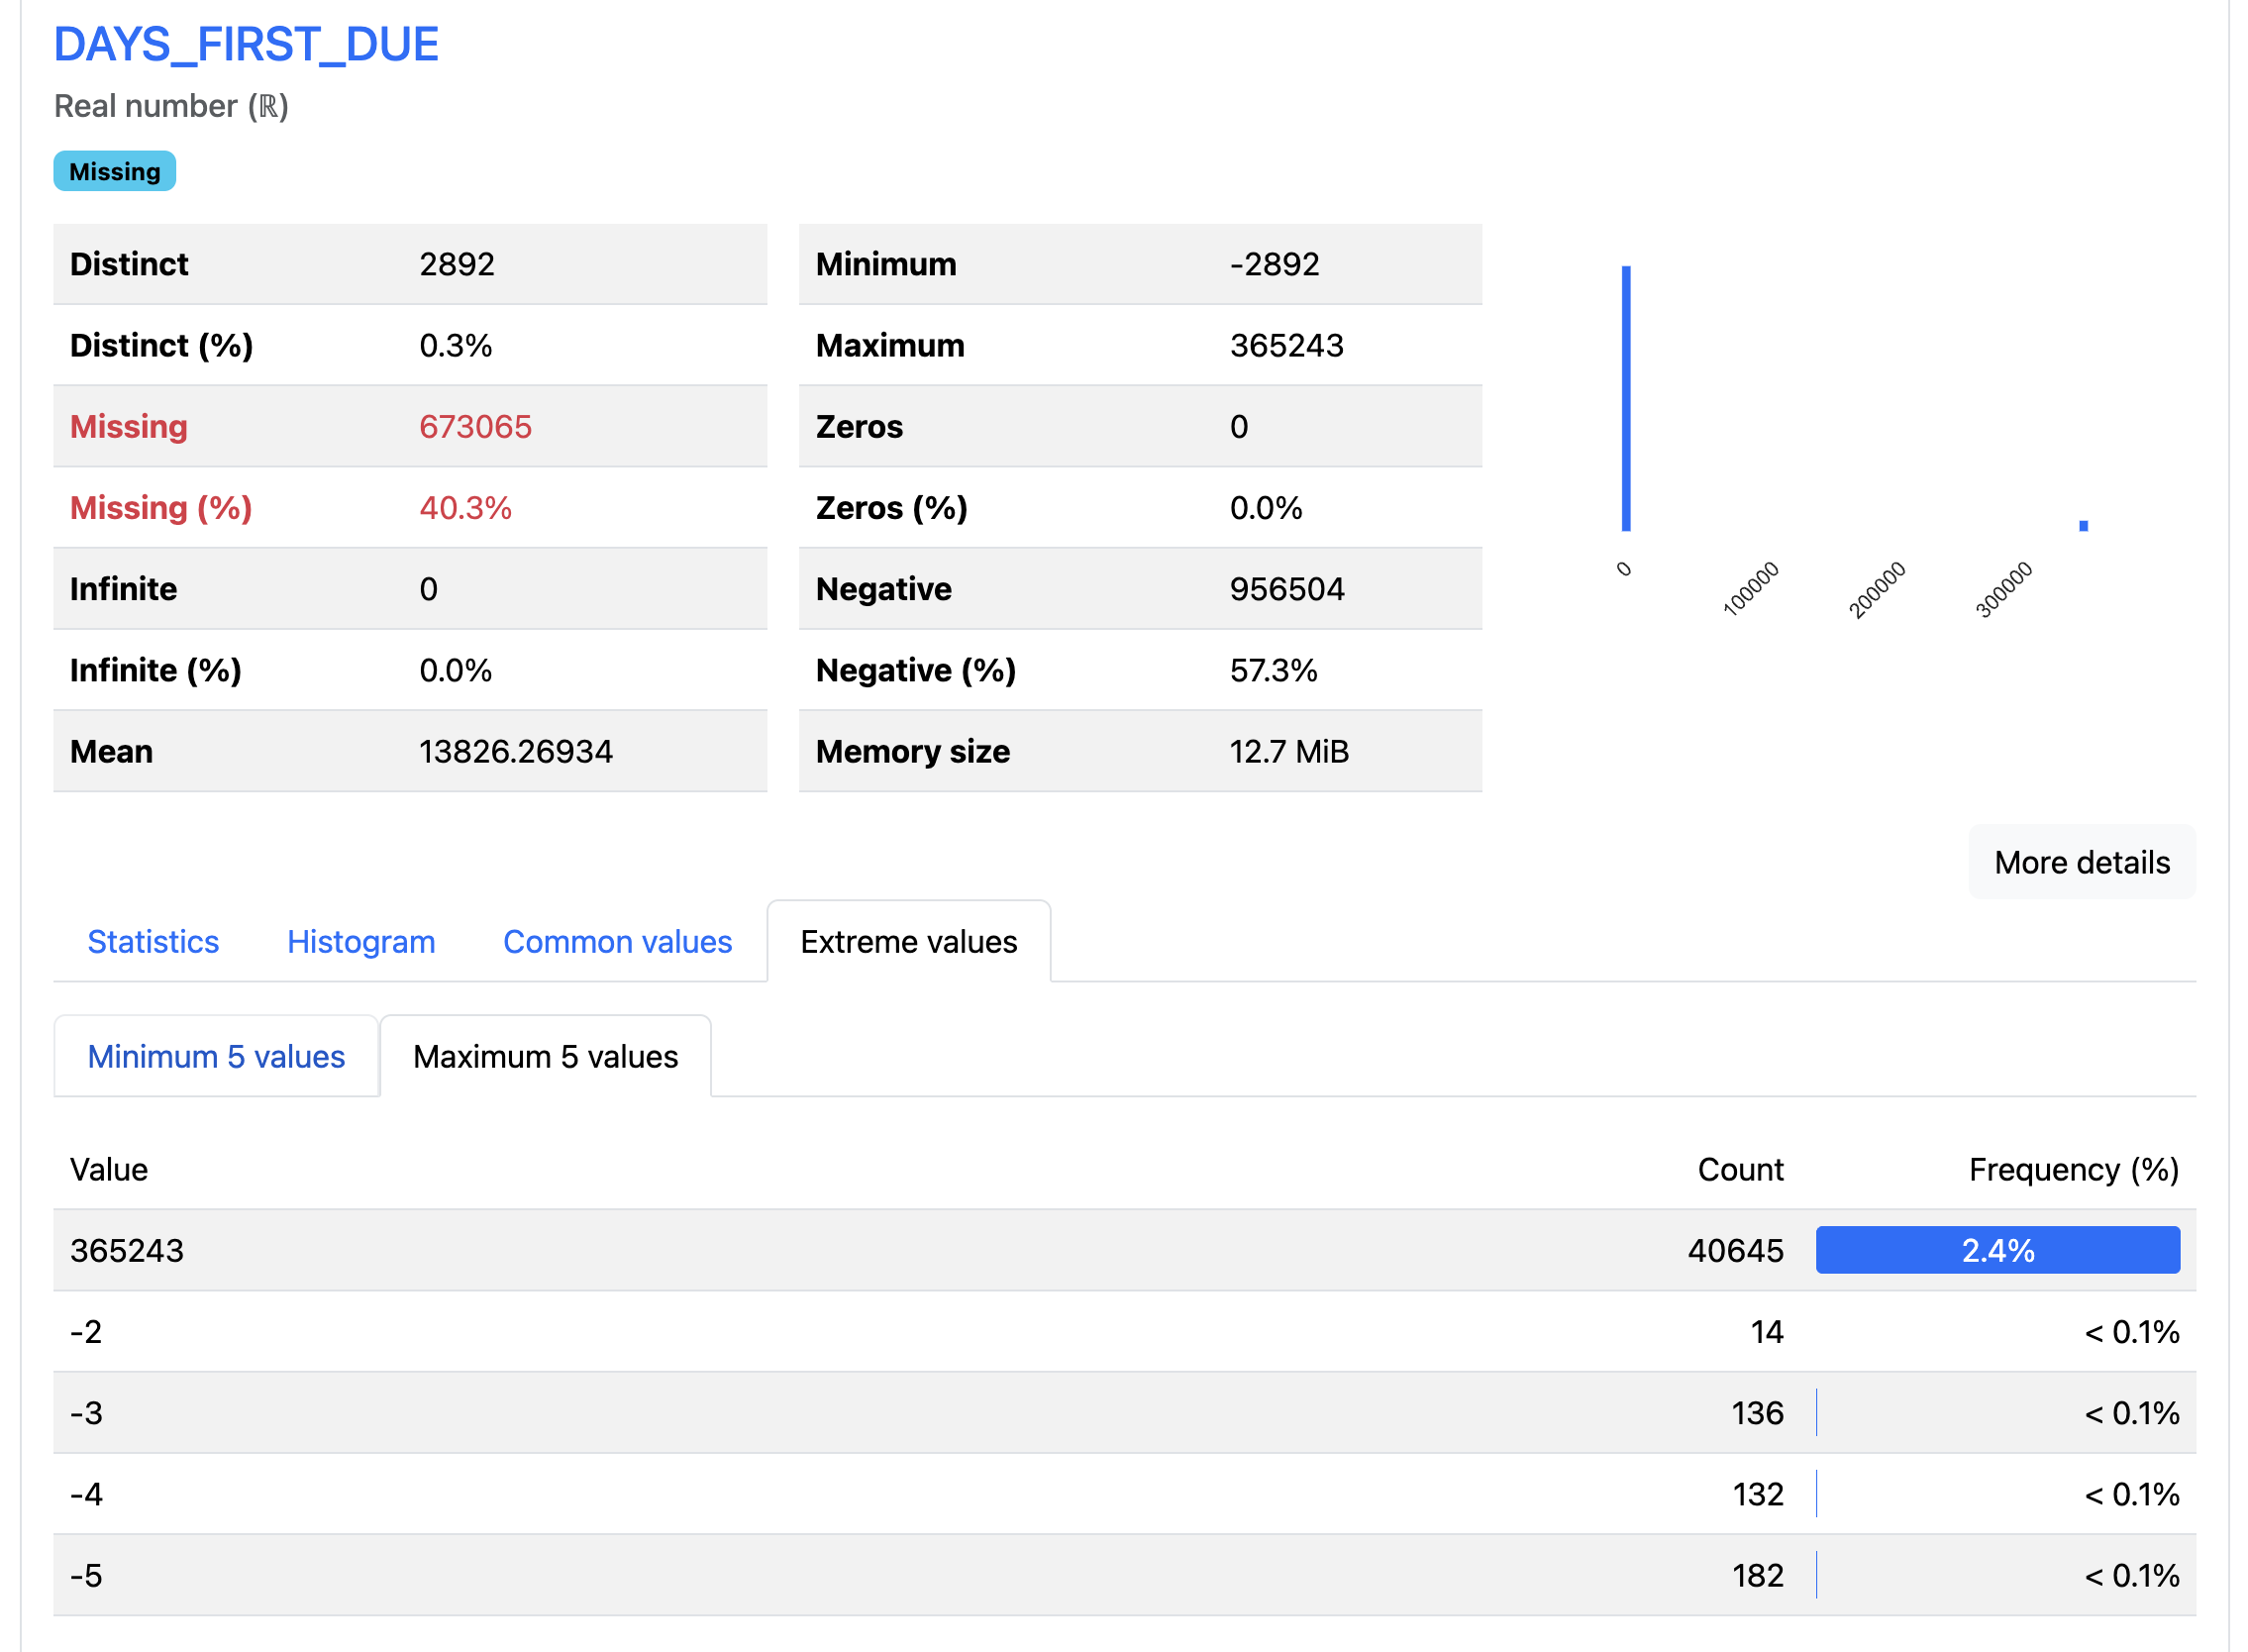

</div>

**Что можно сделать:**
1. Вынести факт аномалии в отдельный бинарный столбец-флаг, а само значение превратить в NaN или 0.

---

## **4. bureau_balance.csv (Ежемесячная история кредитов из БКИ).**

#### **Таблица слишком велика для обработки "в лоб" и содержит абстрактные статусы.**

Переменная STATUS содержит символы: 0 (нет просрочки), 1 (просрочка 1-30 дней), 2, 3, 4, 5 (глубокие просрочки), C (закрыт), X (статус неизвестен).

<div style="max-width: 600px;">

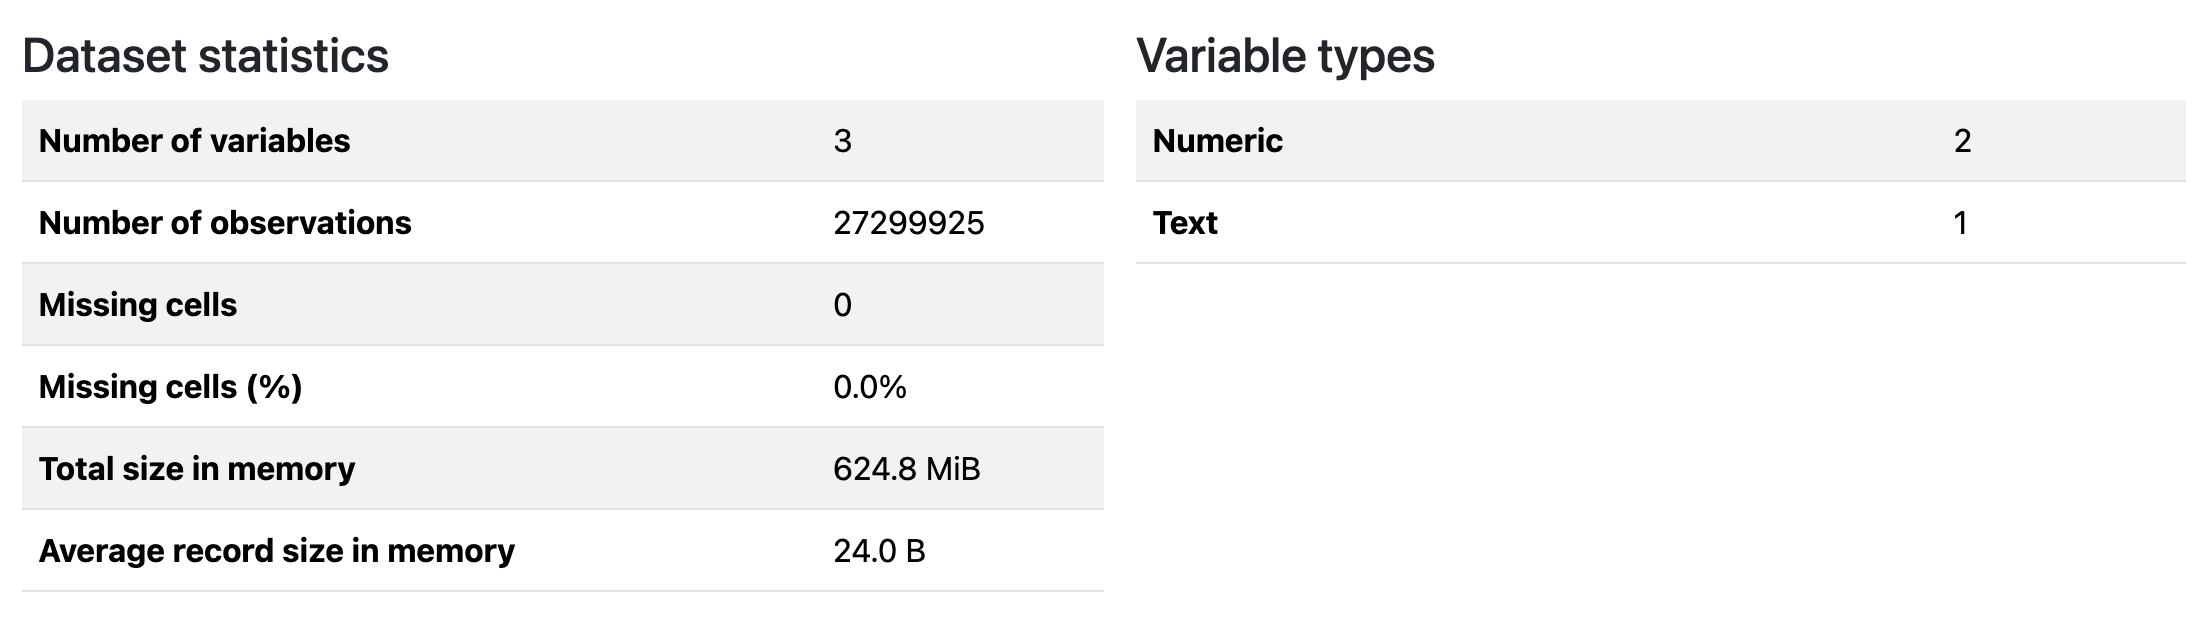

</div>

STATUS:

<div style="max-width: 550px;">

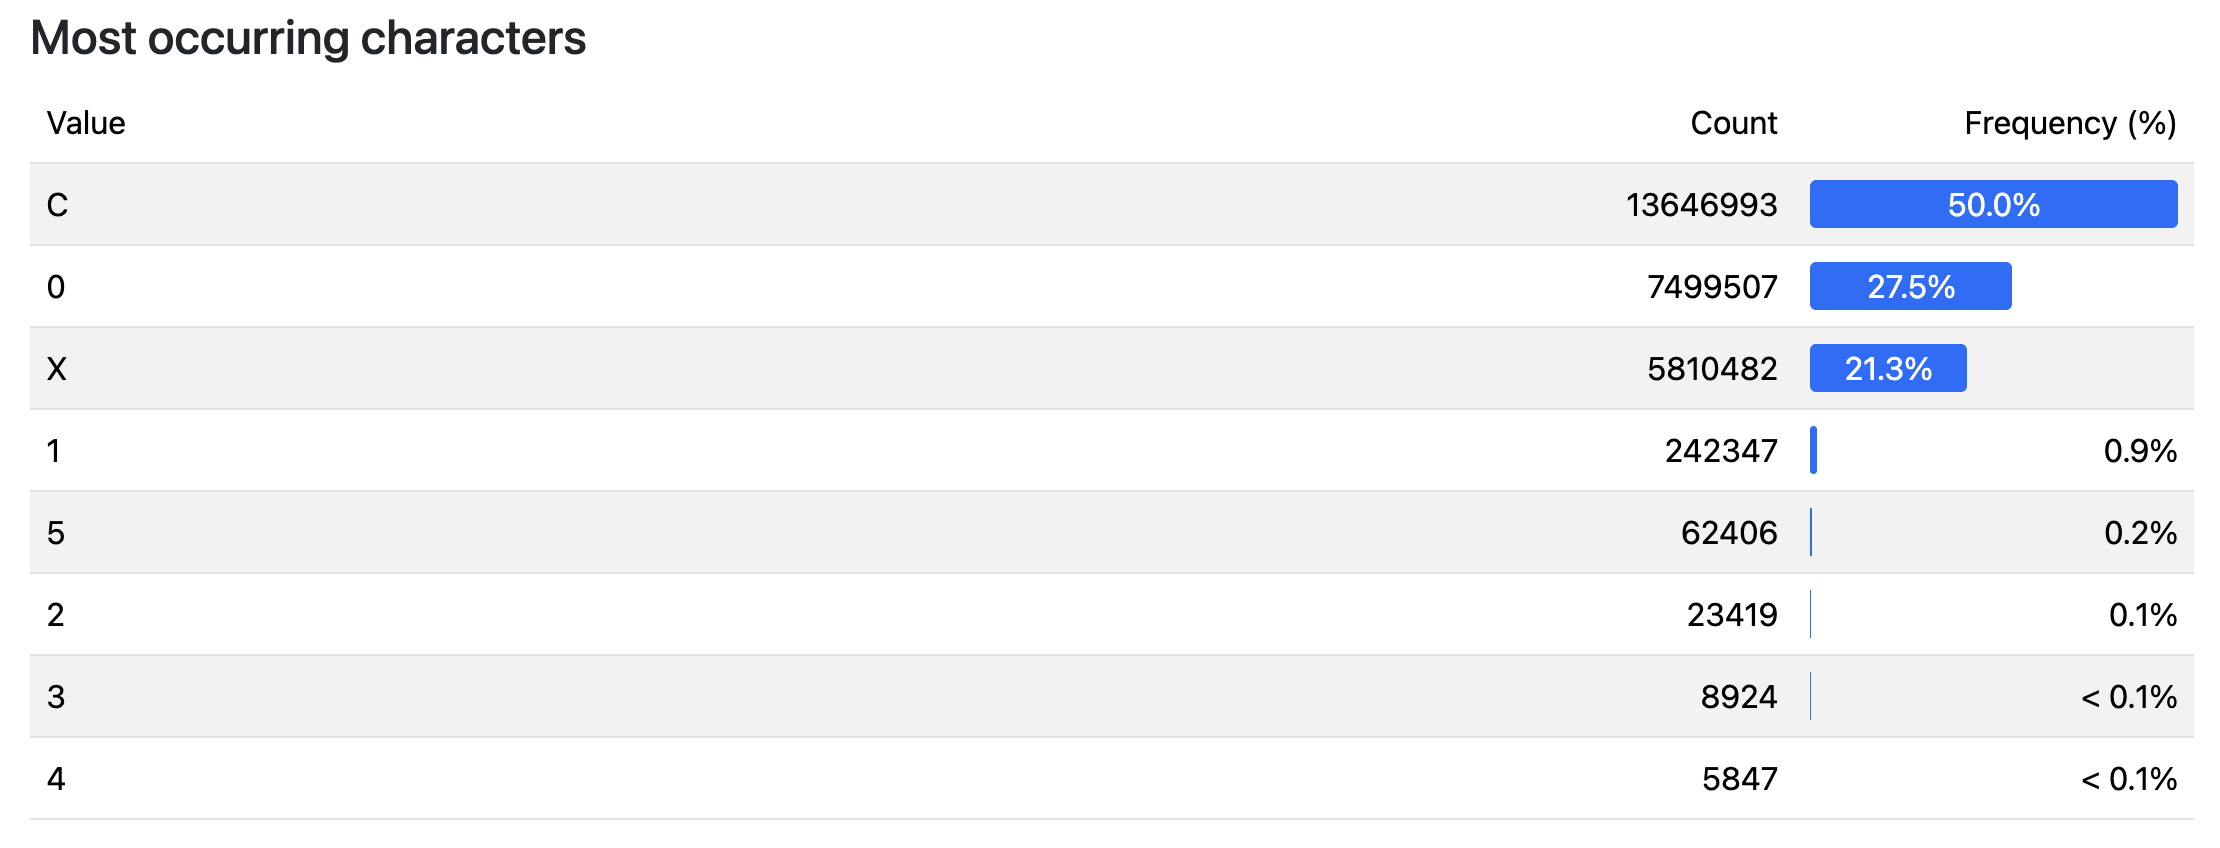

</div>

**Что можно сделать:**

1. Применить One-Hot Encoding (OHE) к колонке STATUS.
2. Сгруппировать таблицу по SK_ID_BUREAU (ID кредита) и посчитать агрегаты: сколько месяцев кредит находился в статусе 1, 2..., как давно кредит был закрыт (статус C).
3. Полученные признаки объединить с таблицей bureau.csv, и только после этого снова сагрегируй по SK_ID_CURR для итоговой модели.

---

Перейдем к **динамическим (поведенческим)** таблицам

В отличие от первой порции таблиц, здесь данные представлены в виде помесячных срезов или истории транзакций (связь «один ко многим» к клиенту).


## **5. credit_card_balance.csv (История по кредитным картам)**


#### **Огромное количество нулей и пропусков.**

<div style="max-width: 300px;">

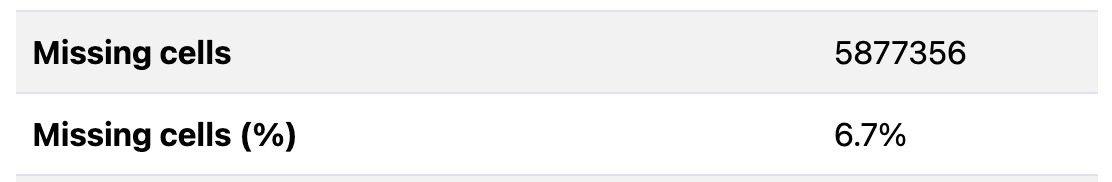

</div>

В основном в полях снятия наличных и задолженностей (например, AMT_DRAWINGS_ATM_CURRENT, AMT_BALANCE).
Профайлинг показывает огромные пики в нуле. Это связано с тем, что многие клиенты не пользуются картой каждый месяц активно или не снимают с нее наличные.

<div style="max-width: 550px;">

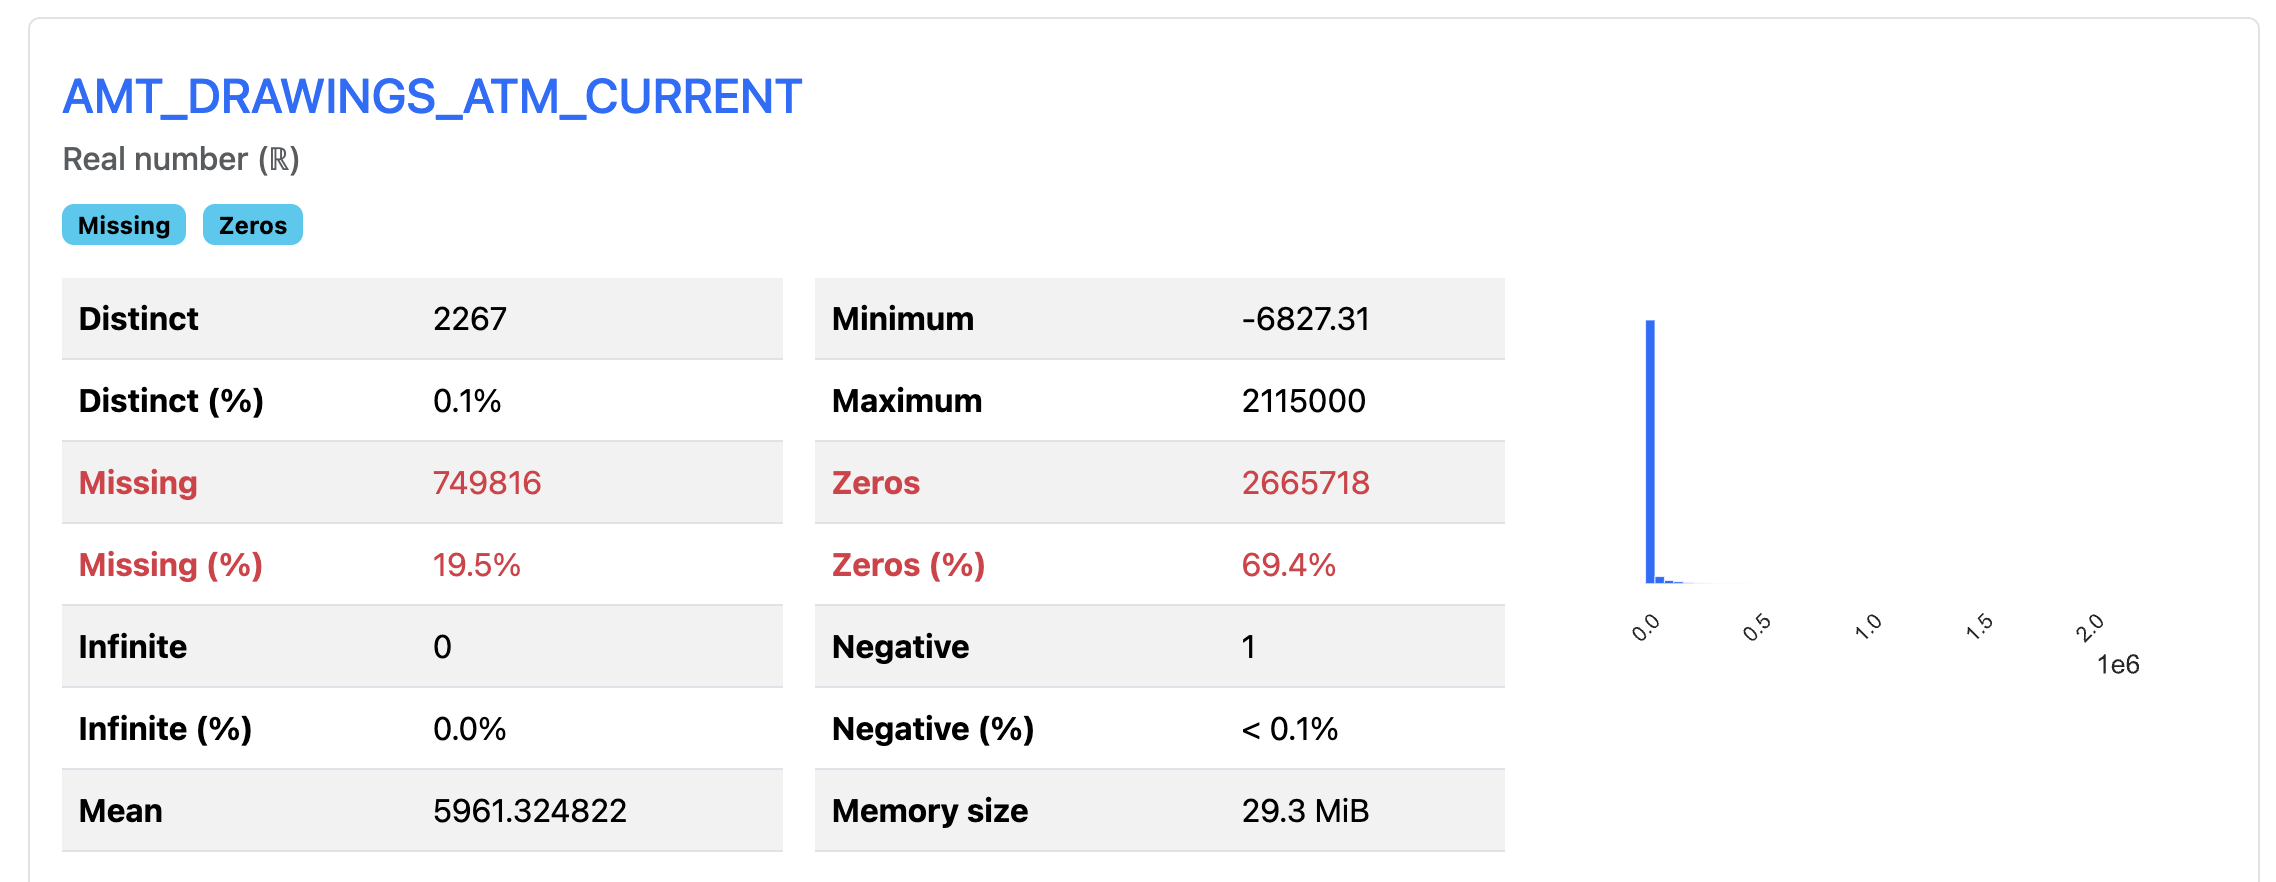

</div>

**Что можно сделать:**

1. Заменить NaN в таких полях на 0 (отсутствие операций в конкретный месяц).
2. Вместо сырых данных создать агрегированный признак: Доля месяцев, в которых баланс был равен нулю и максимальная сумма снятия наличных.

#### **Высокая корреляция (Multicollinearity) между `AMT_BALANCE`, `AMT_RECIVABLE`, `AMT_TOTAL_RECEIVABLE`, `AMT_RECEIVABLE_PRINCIPAL` и `AMT_INST_MIN_REGULARITY`**

### Чтение данных из credit_card_balance.csv

In [ ]:
df_credit_card_balance = pd.read_csv('../data/raw/credit_card_balance.csv')
print('Credit_card_balance data shape: ', df_credit_card_balance.shape)
df_credit_card_balance.head()

### One-Hot-Encoding

In [ ]:
df_credit_card_balance = pd.get_dummies(df_credit_card_balance)
print('Credit_card_balance data shape: ', df_credit_card_balance.shape)

### Корреляции с AMT_BALANCE (общий баланс)

In [ ]:
correlations = df_credit_card_balance.corr()['AMT_BALANCE'].sort_values()
print('Наибольшие положительные корреляции:\n', correlations)

Заметим, что корреляция между `AMT_BALANCE`, `AMT_RECIVABLE`, `AMT_TOTAL_RECEIVABLE`, `AMT_RECEIVABLE_PRINCIPAL` и `AMT_INST_MIN_REGULARITY` близка к 1.0, так как эти признаки описывают одну сущность — долг по карте.

---

## **6. installments_payments.csv (Фактические платежи по кредитам).**

#### **Нет явных NaN, но есть сильный перекос в распределениях и дублирование дат.**

<div style="max-width: 300px;">

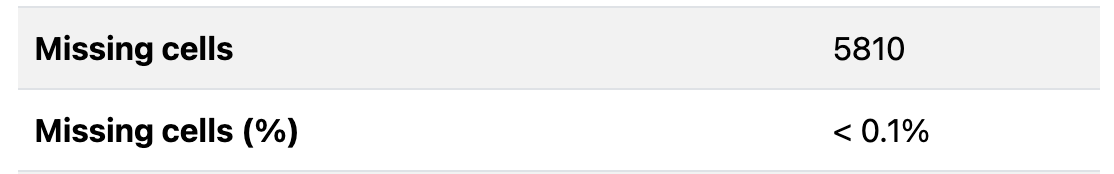

</div>

Поскольку на один плановый платеж клиент мог сделать 2–3 мелких перевода в разные дни, в таблице появляется много строк на одну выплату.

**Что можно сделать:**

1. Эту таблицу нельзя использовать без предварительной математической обработки. Необходимо сконцентрироваться на разнице дат и сумм:

* Создать колонку DAYS_LATE: разница между фактическим днем оплаты (DAYS_ENTRY_PAYMENT) и плановым (DAYS_INSTALMENT). Если значение положительное — это просрочка.
* Создать колонку AMT_LESS: разница между плановой суммой и фактически внесенной. Если клиент недоплатил — это тревожный сигнал.
* При агрегации по клиенту (SK_ID_CURR) посчитатб: максимальное число дней просрочки, среднюю сумму недоплаты и процент платежей, совершенных позже срока.

#### **Экстремальные выбросы (Outliers) в суммах платежей.**

AMT_INSTALMENT (сумма планового платежа): В отчете наблюдается колоссальный разрыв между медианой и максимальным значением. В то время как основная масса платежей сосредоточена в относительно небольшом диапазоне, существуют единичные транзакции на очень крупные суммы (например, при полном досрочном погашении кредита), что сильно смещает распределение вправо.

<div style="max-width: 550px;">

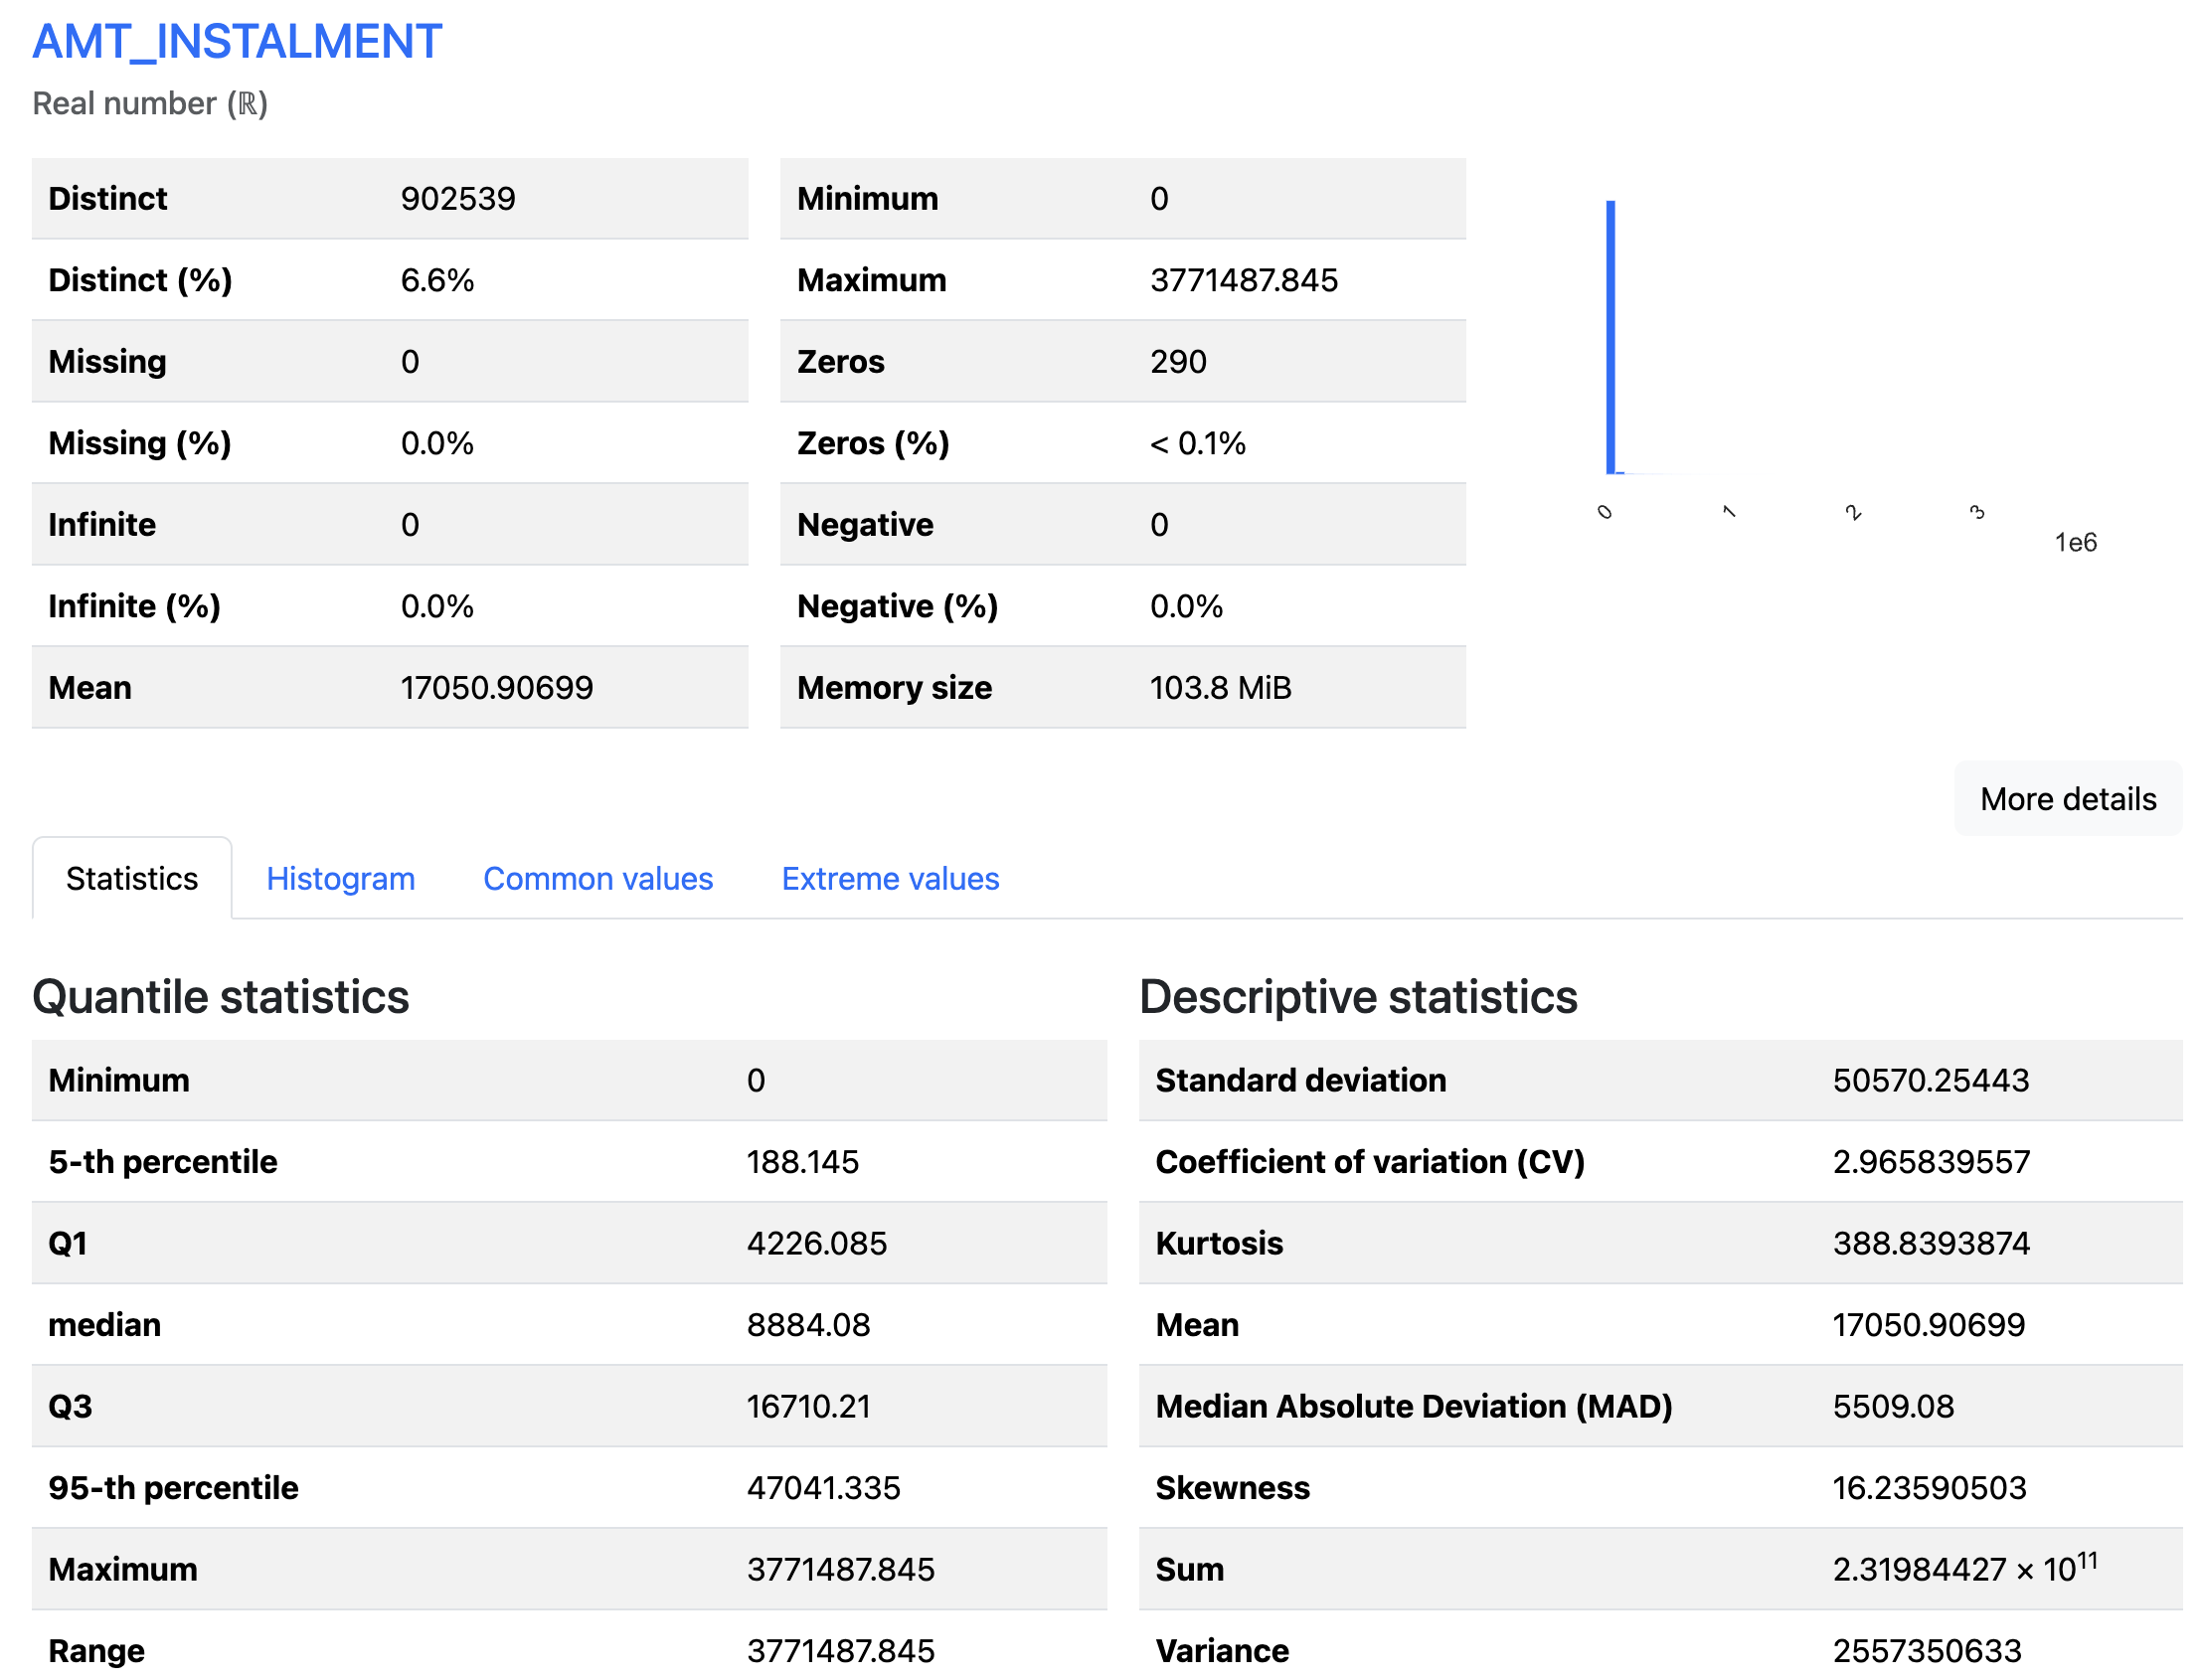

</div>

AMT_PAYMENT (фактически выплаченная сумма): Аналогично плановым суммам, здесь присутствуют экстремальные значения, соответствующие крупным разовым взносам. На графиках распределения это выглядит как узкий высокий пик около нуля и длинный, почти невидимый «хвост», тянущийся к миллионным значениям.

<div style="max-width: 550px;">

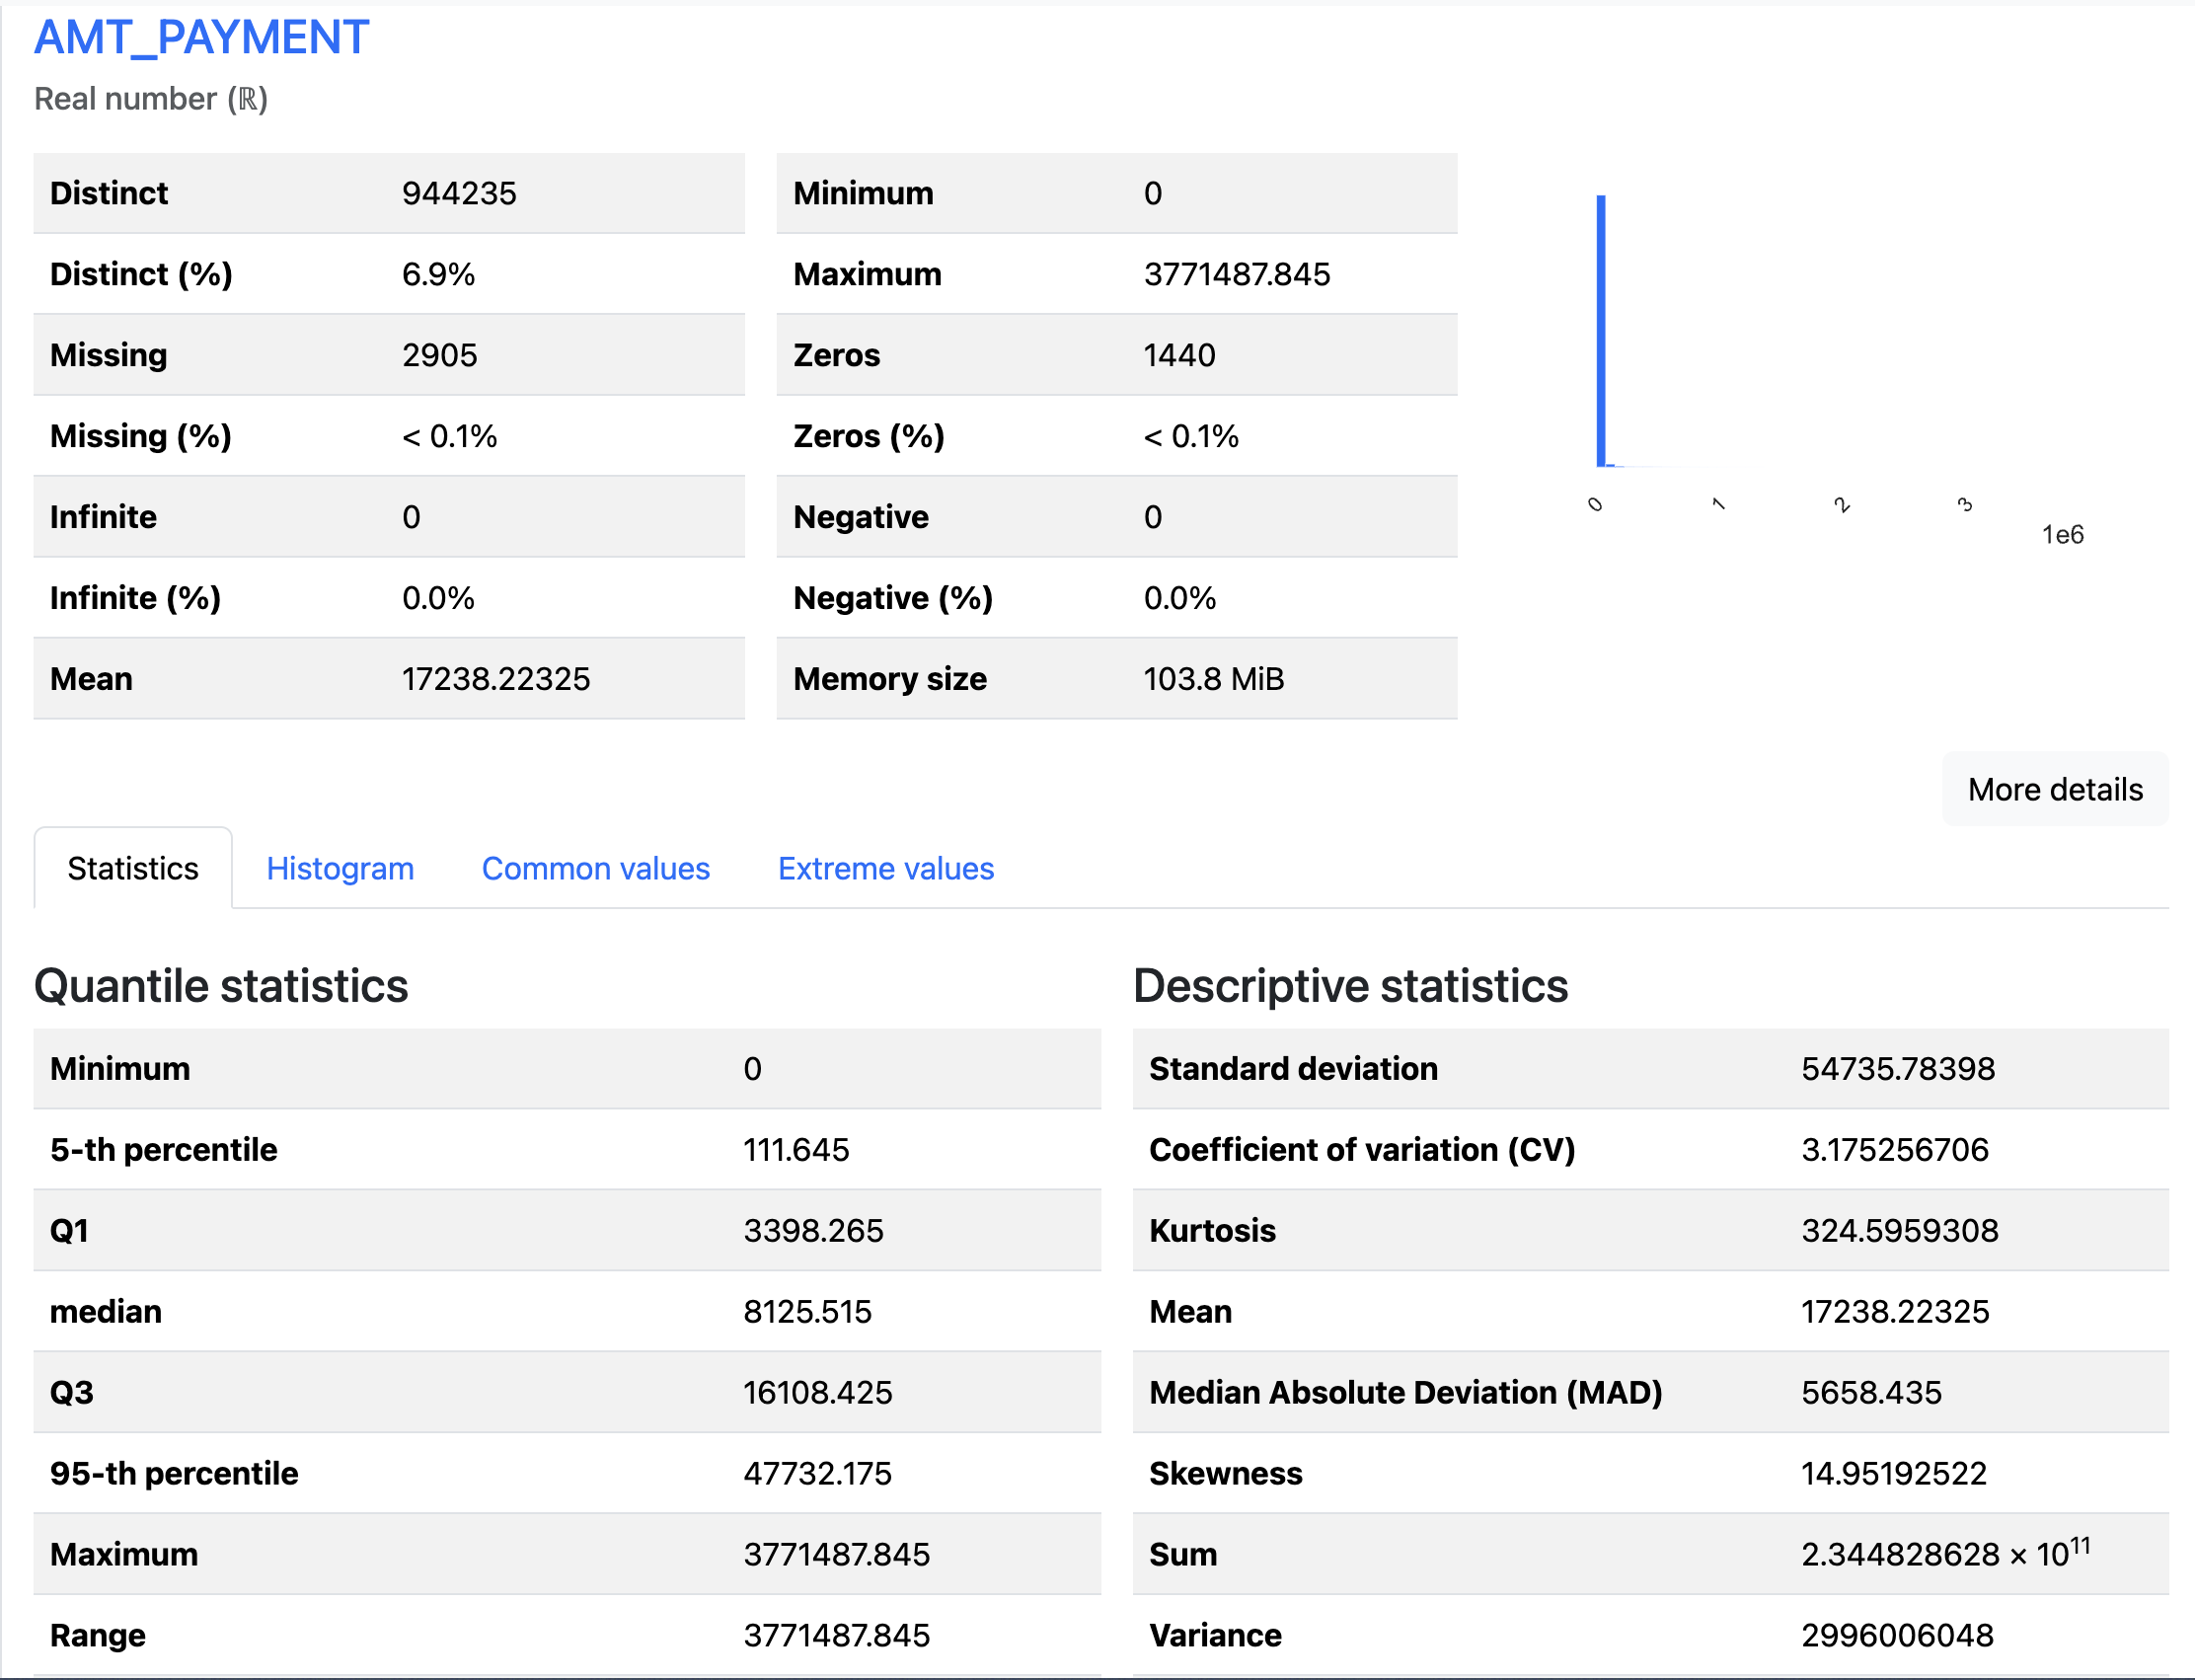

</div>

**Что можно сделать:**

1. Деревья решений (XGBoost, LightGBM) устойчивы к выбросам, но для других моделей стоит применить логарифмирование признаков сумм (np.log1p), чтобы сгладить распределение и сделать его более колоколообразным.

### Чтение данных из installments_payments.csv

In [ ]:
df_installments_payments = pd.read_csv('../data/raw/installments_payments.csv')
print('Installments_payments data shape: ', df_installments_payments.shape)
df_installments_payments.head()

### Box plots

In [ ]:
columns = df_installments_payments.columns

fig, axes = plt.subplots(2, 4, figsize=(20, 12))

axes = axes.flatten()

for i, col in enumerate(columns):
    if i < len(axes):
        sns.boxplot(y=df_installments_payments[col], ax=axes[i])
        axes[i].set_title(col, fontsize=12)
        axes[i].set_ylabel('')
        axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

`NUM_INSTALMENT_VERSION` (Версия графика)

Изменение версии означает пересчет графика платежей (реструктуризация, изменение условий, досрочное погашение).

Значение 0: Специфический маркер для кредитных карт (нет фиксированного графика).

Выбросы (до 178): Индикатор высокой финансовой нестабильности. Частые изменения графика обычно коррелируют с трудностями в выплатах и высоким кредитным риском.

`NUM_INSTALMENT_NUMBER` (Номер платежа)

Что это: Порядковый номер выплаты в рамках одного кредита.

Выбросы (до 277): Свидетельствуют о наличии в портфеле «длинных» кредитов (например, ипотека на 20+ лет) или займов с высокой частотой выплат (еженедельные платежи).

---

## **7. POS_CASH_balance.csv (История потребительских кредитов).**

#### **Высокая кардинальность и дублирование статусов в NAME_CONTRACT_STATUS.**
В отчете будет видно преобладание статусов Active и Completed, но также присутствуют редкие статусы вроде Signed или Returned to the store.

<div style="max-width: 350px;">

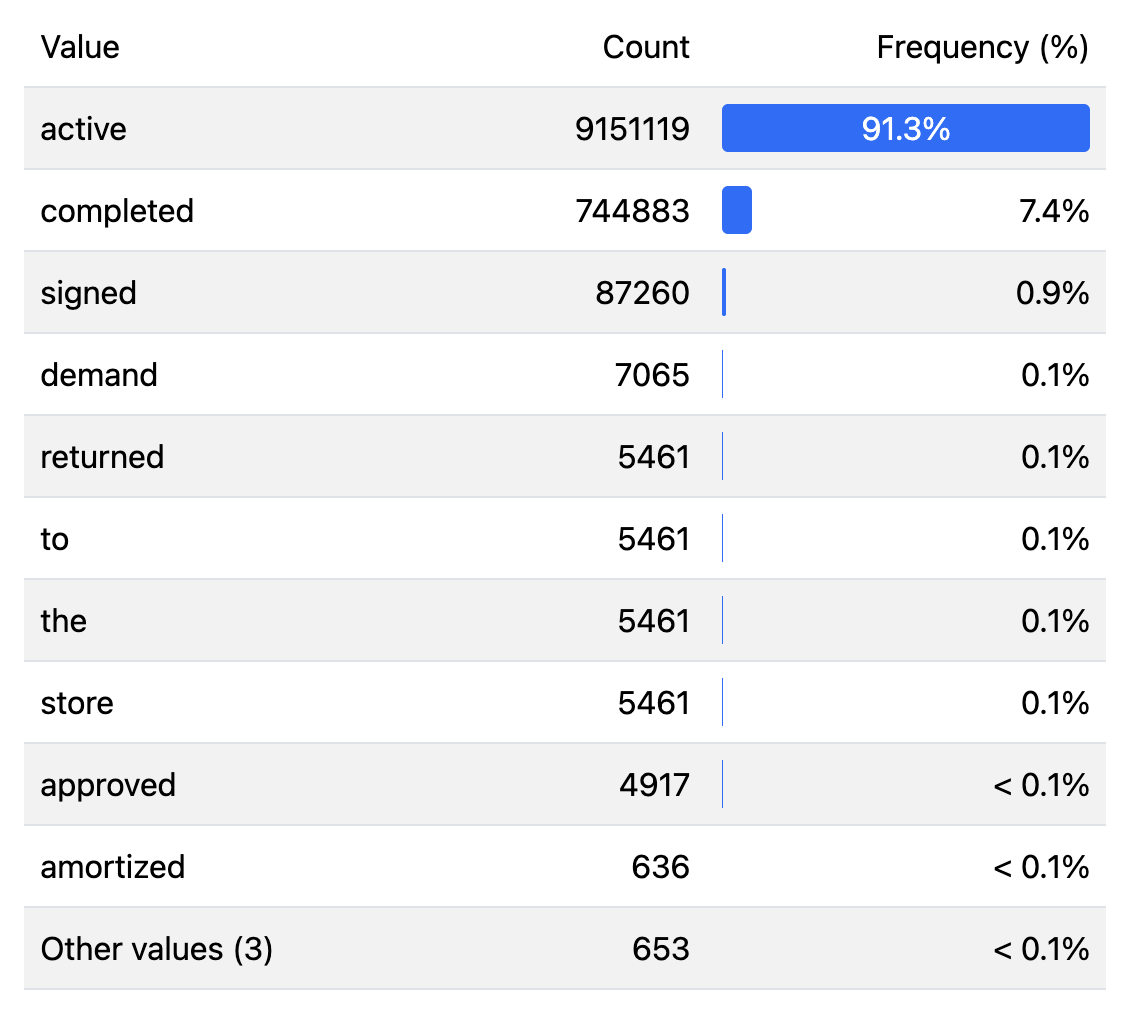

</div>

**Что можно сделать:**

1. Сделать One-Hot Encoding для этой переменной.
2. При группировке по клиенту посчитать, сколько у него прямо сейчас активных кредитов в точках продаж. Если у человека параллельно открыто 5 рассрочек на технику — его кредитоспособность под большим вопросом.

#### **Поле CNT_INSTALMENT_FUTURE (Оставшееся число платежей) содержит много нулей.**

Часто это просто означает, что кредит уже выплачен.

<div style="max-width: 600px;">

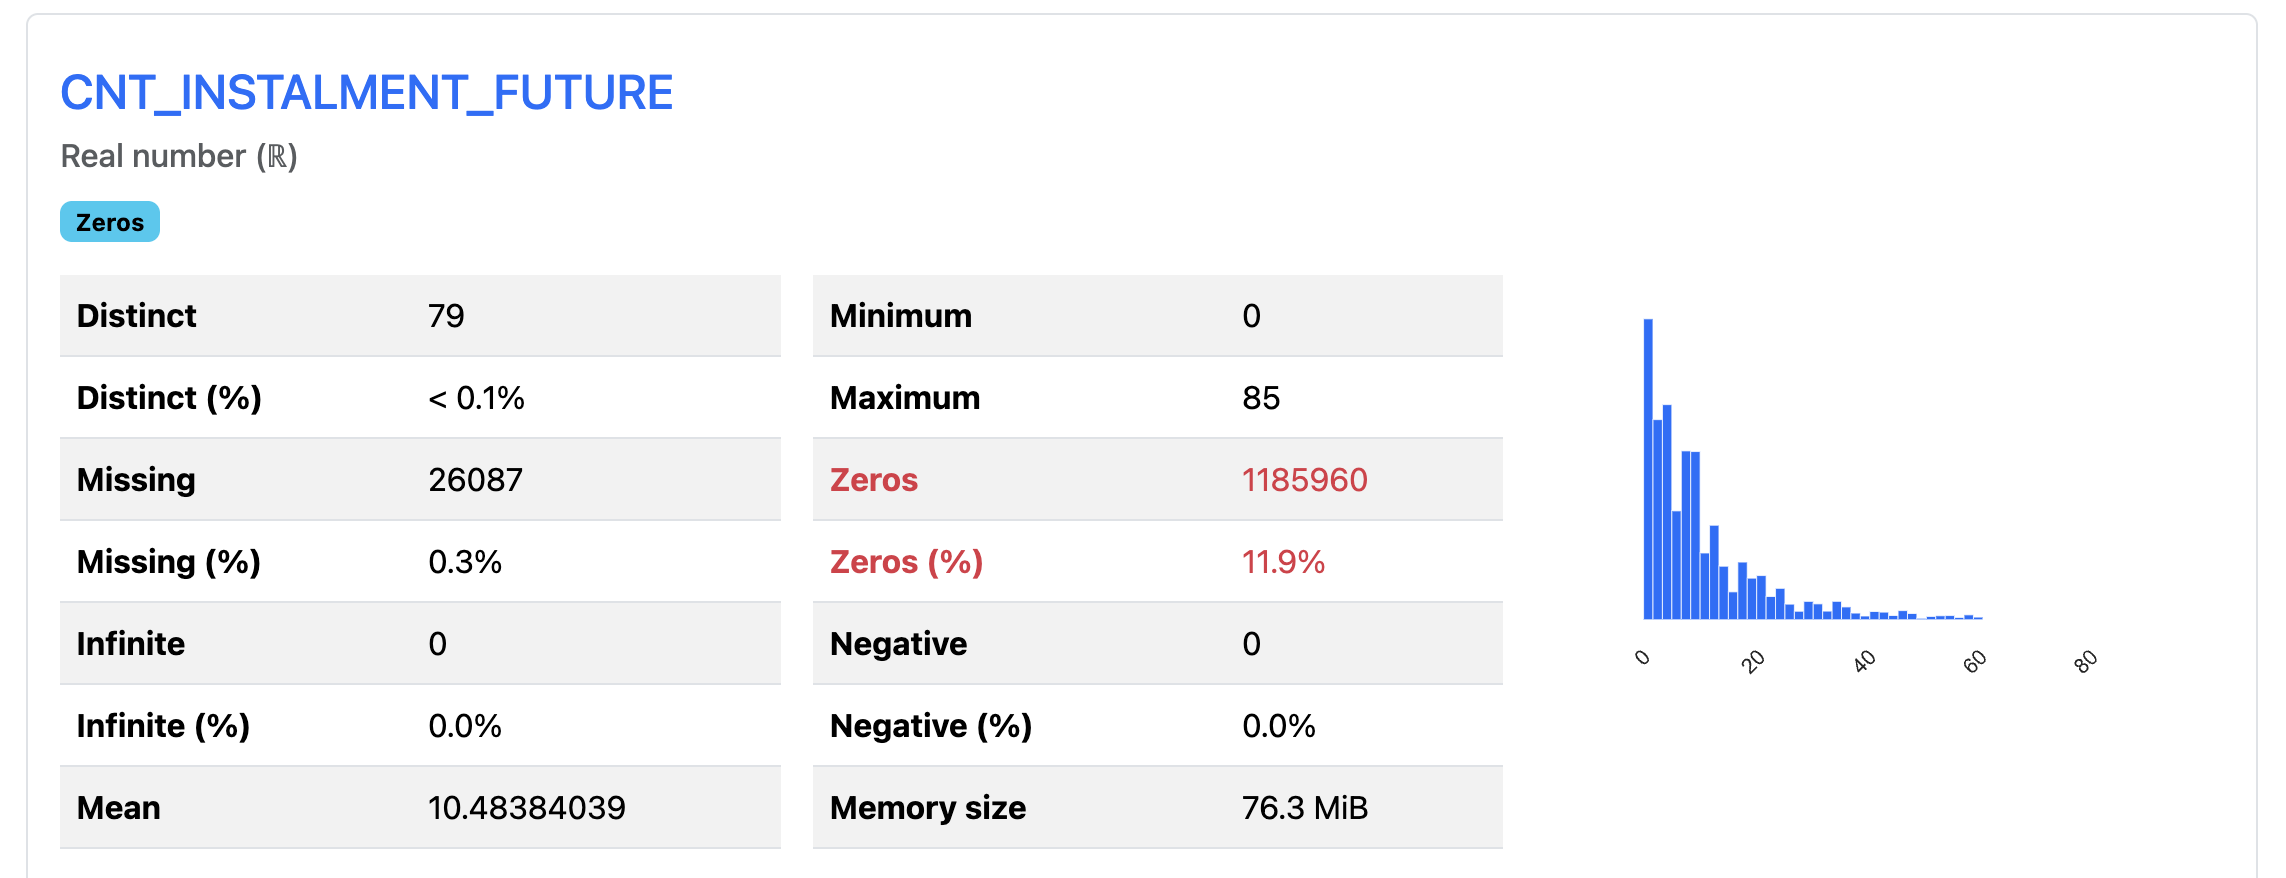

</div>

**Что можно сделать:**

1. Посчитать среднюю скорость погашения кредитов клиентом или выделить максимальный срок, который ему оставалось платить на момент фиксации данных.